# **Dubai Real Estate Sale Price Prediction Using TensorFlow and Keras**

The dataset contains **50,000 Dubai secondary real-estate sales records** with **29 attributes**. It includes property, location, geographical, and market-related information such as area, rooms, bedrooms, floor, parking, community, property type, furnishing, latitude, longitude, and distance to landmarks. The target variable is **`price_usd`**, representing the property's sale price. Since the target is a continuous numerical value, this project is formulated as a **regression problem** using TensorFlow and Keras.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import pandas as pd

I0000 00:00:1792766298.399758     355 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792766300.304912     355 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
df = pd.read_csv("secondary_sales.csv")

# Safety check on the raw file (must stay in this cell, before any cleaning)
assert df.shape == (50000, 29), f"CSV looks incomplete or corrupted: {df.shape}"
assert df["price_usd"].notna().all(), "Some rows have no price; re-upload the CSV"
df

,id,date_listed,community,zone,is_freehold,lat,lon,property_category,property_type,bedrooms,...,chiller_included,metro_station,metro_line,metro_distance_min,metro_distance_type,to_burj_khalifa_km,price_usd,price_per_sqft_usd,price_per_m2_usd,mortgage_rate_at_listing
0,S000001,2024-11-23,DIFC,DIFC,True,25.21053,55.29453,apartment,4BR_penthouse,4,...,True,Financial Centre,Red,6,walk,2.51,4806100,1314,14141,6.15
1,S000002,2023-07-05,DIFC,DIFC,True,25.21330,55.28617,apartment,3BR,3,...,True,Emirates Towers,Red,13,walk,2.15,2287400,1283,13813,6.90
2,S000003,2022-01-22,Karama,Bur Dubai,False,25.24835,55.29501,apartment,1BR,1,...,False,BurJuman (G),Green,14,walk,6.05,167100,203,2184,1.90
3,S000004,2021-10-28,The Valley,Dubai-Al Ain Road,True,24.95989,55.48870,villa,5BR_villa,5,...,False,Discovery Gardens,Red,151,drive,34.09,832000,154,1658,1.90
4,S000005,2025-05-30,Sobha Hartland,MBR City,True,25.17393,55.28697,apartment,3BR,3,...,True,Financial Centre,Red,23,drive,2.88,1323400,660,7104,6.15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,S049996,2022-09-23,Al Mamzar,Al Mamzar,False,25.29514,55.33665,apartment,4BR_penthouse,4,...,True,Abu Hail,Red,15,drive,12.56,1175600,301,3243,2.90
49996,S049997,2023-11-04,Jumeirah 2,Jumeirah,True,25.23702,55.24165,villa,5BR_villa,5,...,False,Al Ras,Green,34,drive,5.52,4226600,800,8612,6.90
49997,S049998,2023-08-07,The Meadows,Emirates Living,True,25.05222,55.19738,villa,3BR_villa,3,...,True,Noor Bank,Red,41,drive,17.89,1231600,484,5208,6.90
49998,S049999,2022-10-25,The Springs,Emirates Living,True,25.04398,55.20842,villa,6BR_villa,6,...,True,Sharaf DG,Red,34,drive,18.29,3545200,448,4818,5.90


> **Data validation: a problem we faced**

**Problem:** in one session the training loss was NaN from the first epoch, and all predictions were NaN.

**Diagnosis:** we checked for NaN in the inputs and found one row with 19 empty columns: the CSV had been cut off during upload to Colab.

**Fix:** we re-uploaded a verified copy (10,202,449 bytes, 50,001 lines), restarted the runtime, and added the two `assert` checks above, which stop the notebook immediately if the file is incomplete.

**Lesson:** one bad row is enough to break gradient descent, because a single NaN spreads through the loss to every weight.

# **1. DATA CLEANING**

In [3]:
# Check dataset shape
print("Shape:", df.shape)

# Check data types and missing values
df.info()

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Shape: (50000, 29)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        50000 non-null  str    
 1   date_listed               50000 non-null  str    
 2   community                 50000 non-null  str    
 3   zone                      50000 non-null  str    
 4   is_freehold               50000 non-null  bool   
 5   lat                       50000 non-null  float64
 6   lon                       50000 non-null  float64
 7   property_category         50000 non-null  str    
 8   property_type             50000 non-null  str    
 9   bedrooms                  50000 non-null  int64  
 10  area_sqft                 50000 non-null  int64  
 11  area_m2                   50000 non-null  float64
 12  floor                     32180 non-null  float64
 13  total_floors              32180 non-null  float64
 14

id                              0
date_listed                     0
community                       0
zone                            0
is_freehold                     0
lat                             0
lon                             0
property_category               0
property_type                   0
bedrooms                        0
area_sqft                       0
area_m2                         0
floor                       17820
total_floors                17820
year_built                      0
view                            0
furnishing                      0
condition                       0
parking_spaces                  0
chiller_included                0
metro_station                   0
metro_line                      0
metro_distance_min              0
metro_distance_type             0
to_burj_khalifa_km              0
price_usd                       0
price_per_sqft_usd              0
price_per_m2_usd                0
mortgage_rate_at_listing        0
dtype: int64


We checked the shape, data types, duplicates and missing values. The dataset has 50,000 rows and 29 columns with no duplicate rows. The only missing values are in floor and total_floors (17,820 each), which we handle below.

In [4]:
# area_m2 is area_sqft in different units (correlation = 1.0), so it adds nothing
df = df.drop(columns=["id", "area_m2"])

Removed the id column, which is only a record identifier and gives no information about price. Also removed area_m2, which is the same as area_sqft in different units (correlation = 1.0), so keeping both would add a duplicate feature.

In [5]:
df["date_listed"] = pd.to_datetime(df["date_listed"])

df["listing_year"] = df["date_listed"].dt.year
df["listing_month"] = df["date_listed"].dt.month

# Remove the original date column
df = df.drop(columns=["date_listed"])

date_listed is stored as text, so we converted it to a datetime type. This lets us extract the listing year and listing month as numeric features, which can capture how prices change over time. The original date column is then removed.

In [6]:
# Check which property types the missing floor values belong to
print(pd.crosstab(df["property_category"], df["floor"].isnull(), colnames=["floor is missing"]))

floor is missing   False  True 
property_category              
apartment          32180      0
villa                  0  17820


The table shows that **every missing `floor` value belongs to a villa**, and every apartment has a floor value. So these gaps are not lost data: `floor` and `total_floors` describe an apartment's floor and the height of its building, which do not apply to villas.

In [7]:
# Villas have no floor number, so the gaps are expected, not missing data
df.loc[df["property_category"] == "villa", ["floor", "total_floors"]] = 0

We set `floor` and `total_floors` to **0 for villas**. No apartment uses this value (apartment floors start at 1 and buildings have at least 20 floors), so 0 clearly means "not applicable", and `property_category` lets the model tell villas and apartments apart. Filling the gaps with the median (18) would have wrongly placed every villa on the 18th floor of an 18-storey building.

In [8]:
#Check the cleaned data
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicates after cleaning:", df.duplicated().sum())

print("\nNew shape:", df.shape)

Missing values after cleaning:
community                   0
zone                        0
is_freehold                 0
lat                         0
lon                         0
property_category           0
property_type               0
bedrooms                    0
area_sqft                   0
floor                       0
total_floors                0
year_built                  0
view                        0
furnishing                  0
condition                   0
parking_spaces              0
chiller_included            0
metro_station               0
metro_line                  0
metro_distance_min          0
metro_distance_type         0
to_burj_khalifa_km          0
price_usd                   0
price_per_sqft_usd          0
price_per_m2_usd            0
mortgage_rate_at_listing    0
listing_year                0
listing_month               0
dtype: int64



Duplicates after cleaning: 0

New shape: (50000, 28)


After cleaning, the dataset has **no missing values and no duplicates**, with 50,000 rows and 28 columns, and is ready for exploration.

# **2. Exploratory Data Analysis (EDA)**

EDA is the process of exploring and understanding the dataset using statistics and visualizations before building the machine learning model.

> **Target variable analysis - Price**

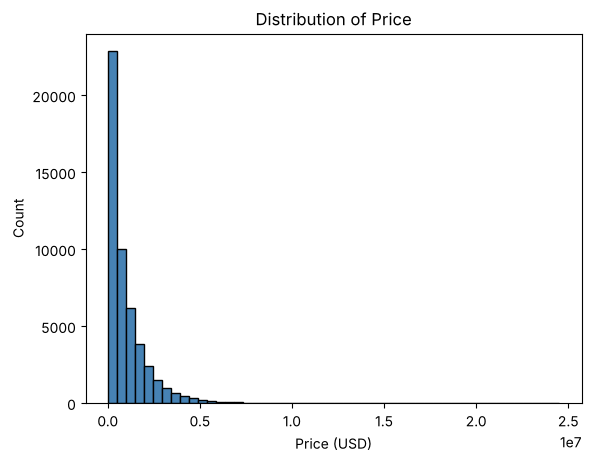


Mean: 1014038.04
Median: 593700.0
Skewness: 3.69


In [9]:
#Price histogram Mean / median / skewness
plt.hist(df['price_usd'], bins=50, color='steelblue', edgecolor='black')
plt.xlabel('Price (USD)')
plt.ylabel('Count')
plt.title('Distribution of Price')
plt.show()

print("\nMean:", round(df['price_usd'].mean(), 2))
print("Median:", round(df['price_usd'].median(), 2))
print("Skewness:", round(df['price_usd'].skew(), 2))

Property prices are **strongly right-skewed**: the mean (about \$1.01M) is much higher than the median (about \$594K), and the skewness is 3.69. Most properties sell below \$1M, while a smaller number of luxury properties stretch the distribution up to \$24.5M.

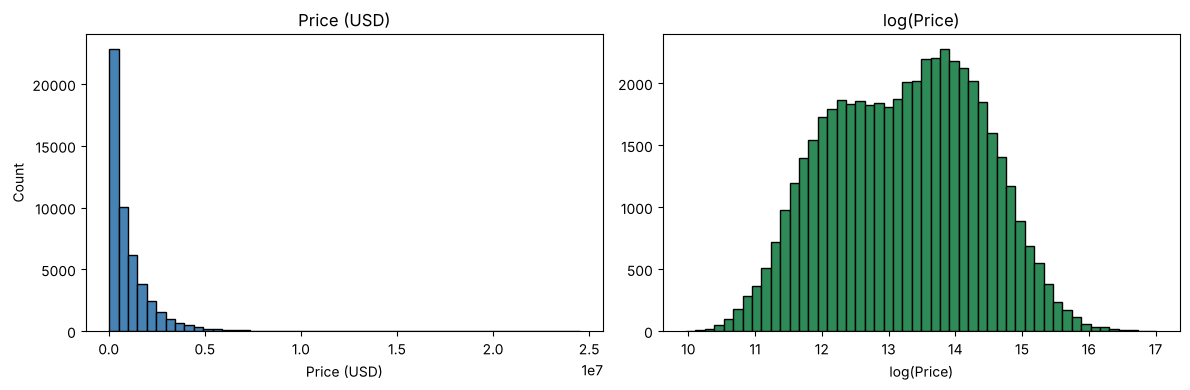

Skewness before: 3.69
Skewness after log: -0.05


In [10]:
# Compare raw price with log(price)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["price_usd"], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title("Price (USD)")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Count")

axes[1].hist(np.log(df["price_usd"]), bins=50, color="seagreen", edgecolor="black")
axes[1].set_title("log(Price)")
axes[1].set_xlabel("log(Price)")

plt.tight_layout()
plt.show()

print("Skewness before:", round(df["price_usd"].skew(), 2))
print("Skewness after log:", round(np.log(df["price_usd"]).skew(), 2))

After a log transform, the skewness drops from 3.69 to about **−0.05**, so the distribution becomes close to symmetric. A neural network trains more stably on a target like this, so we will **train the model on log(price)** and convert its predictions back to USD for evaluation.

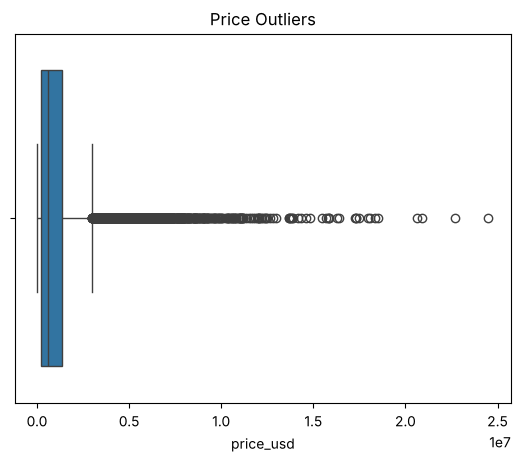

In [11]:
#Price boxplot
sns.boxplot(x=df['price_usd'])
plt.title('Price Outliers')
plt.show()

The boxplot shows many points above the upper whisker, which are high-priced properties. We use the IQR method below to count them.

In [12]:
#IQR outliers
Q1 = df['price_usd'].quantile(0.25)
Q3 = df['price_usd'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['price_usd'] < Q1 - 1.5*IQR) | (df['price_usd'] > Q3 + 1.5*IQR)]
print("Outliers:", len(outliers), f"({len(outliers)/len(df)*100:.1f}%)")

# Which property types are the outliers?
print(outliers['property_category'].value_counts())

Outliers: 3077 (6.2%)
property_category
villa        2462
apartment     615
Name: count, dtype: int64


About **6.2%** of properties (3,077) are price outliers, and all of them are on the high side. Most of them are villas, so they are genuine luxury properties rather than data errors. We **keep them** in the data, and training on log(price) reduces their influence on the model.

> **Data quality Check**

In [13]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Minimum price:", df['price_usd'].min())
print("Maximum price:", df['price_usd'].max())

Missing values: 0
Duplicate rows: 0
Minimum price: 21300
Maximum price: 24501200


We check for missing values and duplicate rows to make sure the dataset is clean. We also check the minimum and maximum prices to understand the price range.

The final check confirms no missing values and no duplicates. Prices range from about **\$21K to \$24.5M**, a very wide range that again supports using a log transform.

> **Numerical relationships**

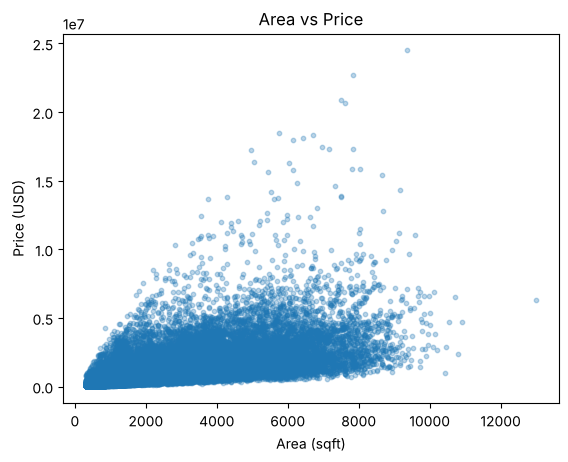

Correlation: 0.653


In [14]:
# Price vs area
plt.scatter(df['area_sqft'], df['price_usd'], alpha=0.3, s=10)
plt.xlabel('Area (sqft)')
plt.ylabel('Price (USD)')
plt.title('Area vs Price')
plt.show()

print("Correlation:", round(df['area_sqft'].corr(df['price_usd']), 3))

Price rises with area: larger properties are clearly more expensive, with a **correlation of 0.65**, making area one of the strongest single predictors of price. The spread also widens for bigger properties, because location and property type matter more at the high end.

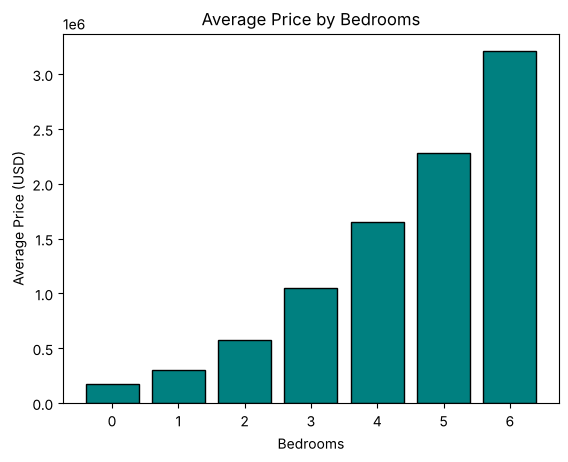

In [15]:
# Price vs bedrooms
avg = df.groupby('bedrooms')['price_usd'].mean()
plt.bar(avg.index, avg.values, color='teal', edgecolor='black')
plt.xlabel('Bedrooms')
plt.ylabel('Average Price (USD)')
plt.title('Average Price by Bedrooms')
plt.show()

Average price increases steadily with the number of bedrooms, from about **\$177K for studios** (0 bedrooms) to about **\$3.2M for 6-bedroom** properties. Bedrooms are therefore a strong predictor, although they overlap heavily with area (see the heatmap below).

> **Categorical relationships**

In [16]:
# Number of categories in each text column
cat_cols = df.select_dtypes(exclude=["number", "bool"]).columns
print(df[cat_cols].nunique().sort_values(ascending=False))

community              84
metro_station          55
zone                   52
property_type           9
view                    8
furnishing              3
condition               3
property_category       2
metro_line              2
metro_distance_type     2
dtype: int64


`community` (84), `metro_station` (55) and `zone` (52) have the most categories, while the other text columns have 9 or fewer. This tells us how many new columns one-hot encoding will create in the preprocessing step.

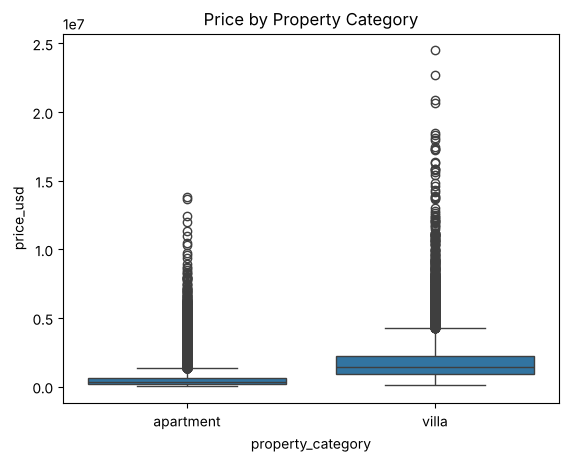

In [17]:
# Price vs property category
sns.boxplot(data=df, x='property_category', y='price_usd')
plt.title('Price by Property Category')
plt.show()

Villas are much more expensive than apartments: the **average villa costs about \$1.82M** compared with about **\$568K for an apartment**. Villa prices also vary much more, which is why most of the outliers are villas.

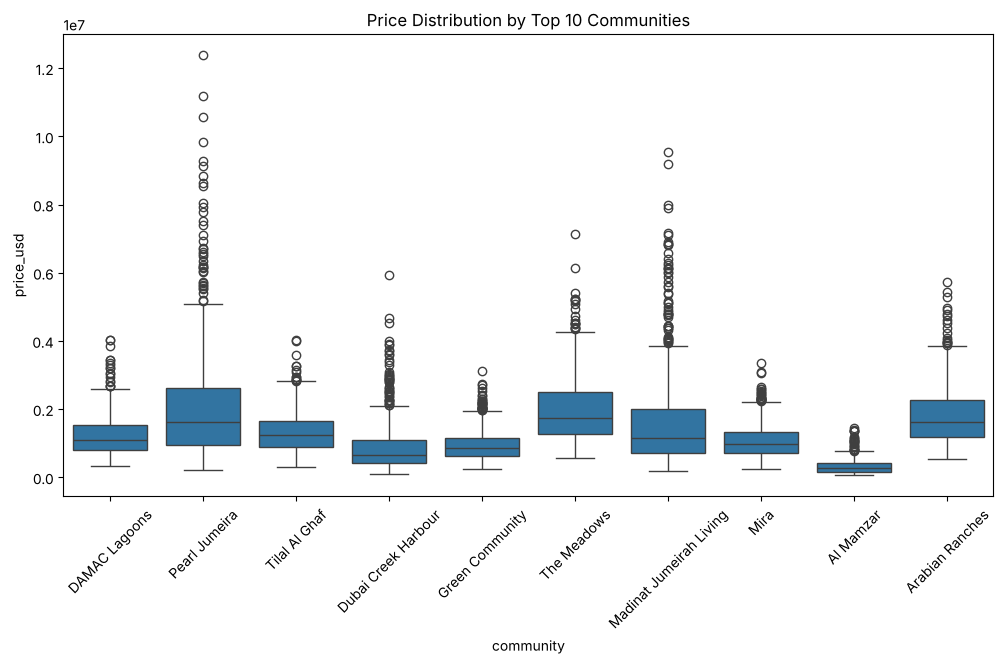

In [18]:
#Top 10 Communities distribution
top_communities = df['community'].value_counts().head(10).index

community_price = df[df['community'].isin(top_communities)]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=community_price,
    x='community',
    y='price_usd'
)

plt.xticks(rotation=45)
plt.title('Price Distribution by Top 10 Communities')
plt.show()

Among the 10 communities with the most listings, median prices range from about **\$260K in Al Mamzar** to about **\$1.74M in The Meadows**. Location strongly affects price, and villa communities (The Meadows, Arabian Ranches) sit at the top. Across all communities, the most expensive is Emirates Hills (median about \$3.5M) and the cheapest is International City (about \$115K).

> **Correlation Analysis**

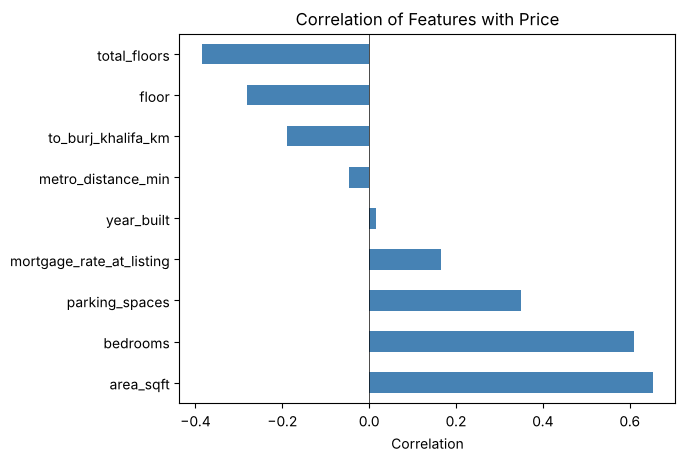

In [19]:
#Correlation of Features with Price
feature_cols = ['bedrooms', 'area_sqft', 'floor', 'total_floors', 'year_built',
                'parking_spaces', 'metro_distance_min', 'to_burj_khalifa_km',
                 'mortgage_rate_at_listing']

price_corr = df[feature_cols + ['price_usd']].corr()['price_usd'].sort_values(ascending=False)
price_corr = price_corr.drop('price_usd')

price_corr.plot(kind='barh', color='steelblue')
plt.title('Correlation of Features with Price')
plt.xlabel('Correlation')
plt.axvline(0, color='black', linewidth=0.5)
plt.show()

**Area (0.65)** and **bedrooms (0.61)** have the strongest positive correlation with price, followed by parking spaces (0.35). Distance to Burj Khalifa is negative (−0.19): properties further from the centre tend to be cheaper.

Two features need care when reading this chart:
- `floor` and `total_floors` look negative, but this is because villas (set to 0) are more expensive than apartments. Within apartments alone, their correlation with price is close to zero (about 0.04–0.06).
- `mortgage_rate_at_listing` looks positive, but both rates and prices rose after 2022, so this mostly reflects the time trend rather than higher rates causing higher prices.

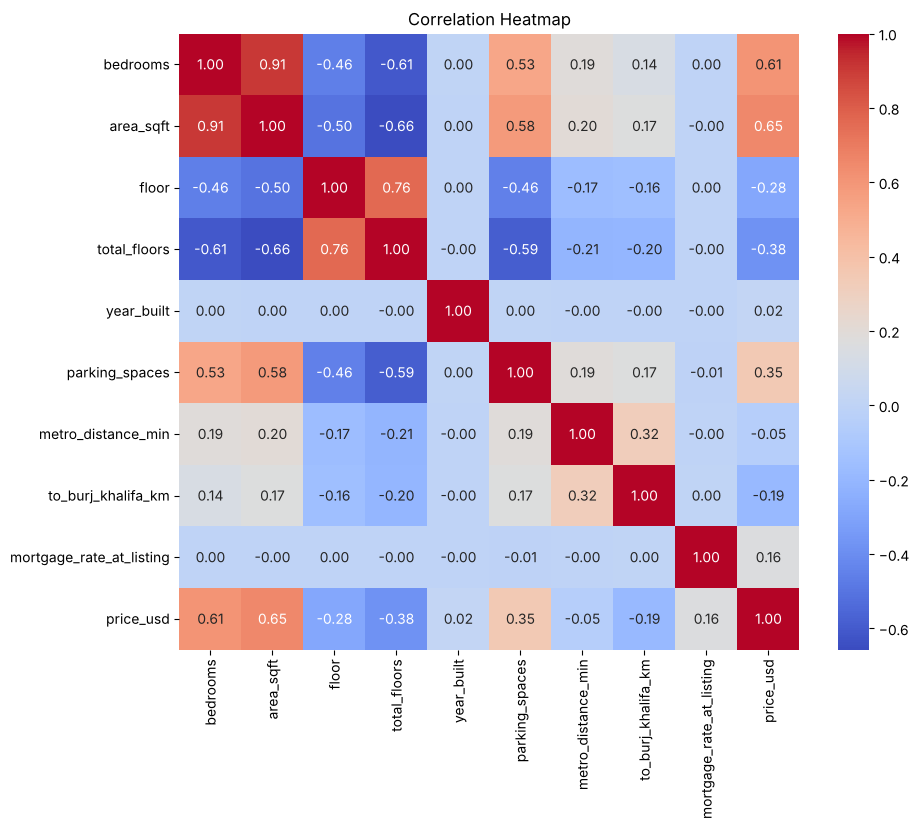

In [20]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df[feature_cols + ['price_usd']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

The heatmap shows the correlations between the numerical features and the target, and helps identify features that are strongly related to each other. **Bedrooms and area are highly correlated with each other (0.91)**, since bigger properties have more bedrooms. They carry overlapping information, but a neural network can handle related inputs, so we keep both. Most other features are only weakly related to each other.

>**Time**

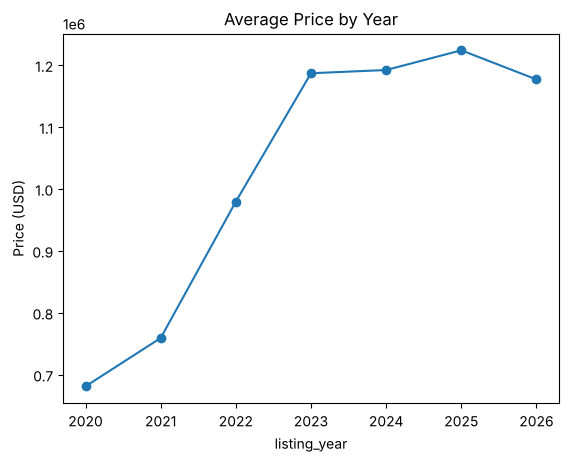

In [21]:
# Average price by year
df.groupby('listing_year')['price_usd'].mean().plot(marker='o')
plt.title('Average Price by Year')
plt.ylabel('Price (USD)')
plt.show()

This graph shows the average property price for each listing year. It helps us identify possible changes or trends in property prices over time.

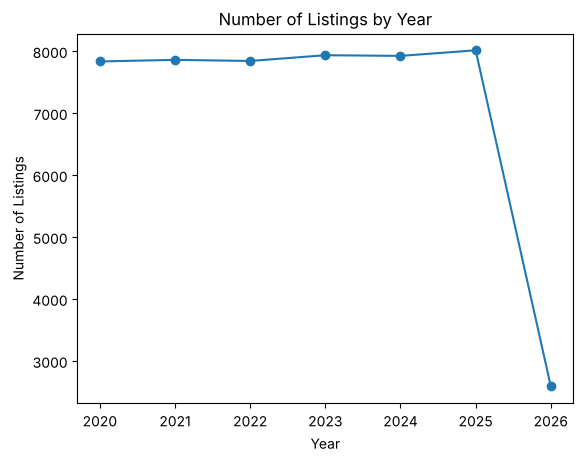

In [22]:
# Number of listings by year
df['listing_year'].value_counts().sort_index().plot(marker='o')

plt.title('Number of Listings by Year')
plt.xlabel('Year')
plt.ylabel('Number of Listings')

plt.show()

This graph shows how many properties were listed in each year. It helps us understand whether the yearly price averages are based on enough data.

>**Location**

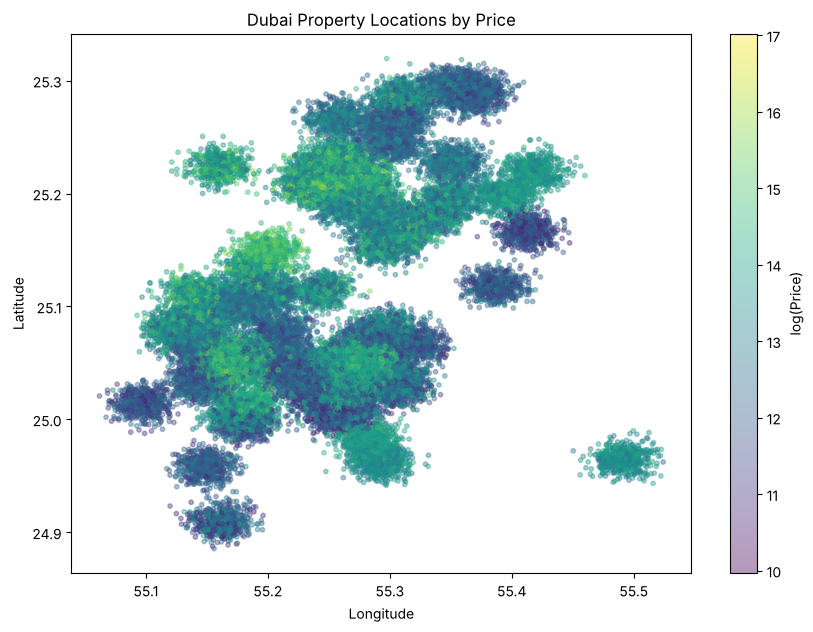

In [23]:
#Location analysis - Latitude/longitude vs price (log scale)
plt.figure(figsize=(10, 7))

plt.scatter(
    df['lon'],
    df['lat'],
    c=np.log(df['price_usd']),
    cmap='viridis',
    alpha=0.4,
    s=10
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Dubai Property Locations by Price')

plt.colorbar(label='log(Price)')

plt.show()

We colour the points by log(price) so the differences are visible across the whole range instead of being dominated by a few very expensive properties. The properties form clear clusters, one for each community, and the colour differs between clusters: some areas are consistently more expensive than others. Within each cluster, prices still vary because of size and property type. Location is therefore an important feature, captured by `lat`, `lon`, `community`, `zone` and `to_burj_khalifa_km`.

>**Data Leakage observation**

In [24]:
#Data leakage
print("Leakage columns to drop later: price_per_sqft_usd, price_per_m2_usd")

Leakage columns to drop later: price_per_sqft_usd, price_per_m2_usd


price_per_sqft_usd and price_per_m2_usd are derived from price_usd.
They will be dropped before modeling to avoid data leakage.

# **3. Data Preprocessing & Feature Engineering**

In this section we prepare the cleaned data for the neural network: we define the inputs and target, split the data, convert text columns to numbers, scale the numeric columns, and build a first baseline model.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fix the random seeds so every run gives the same results (reproducibility)
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

We set a fixed random seed (42) for NumPy and TensorFlow. This makes the data split and the network's starting weights the same on every run, so other groups can reproduce our results exactly.

>**Define X and y**

In [26]:
# Target: what we want to predict, on a log scale
y = np.log(df["price_usd"])

# Features: everything except the target and the leakage columns
leakage_cols = ["price_per_sqft_usd", "price_per_m2_usd"]
X = df.drop(columns=["price_usd"] + leakage_cols)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures used:")
print(list(X.columns))

X shape: (50000, 25)
y shape: (50000,)

Features used:
['community', 'zone', 'is_freehold', 'lat', 'lon', 'property_category', 'property_type', 'bedrooms', 'area_sqft', 'floor', 'total_floors', 'year_built', 'view', 'furnishing', 'condition', 'parking_spaces', 'chiller_included', 'metro_station', 'metro_line', 'metro_distance_min', 'metro_distance_type', 'to_burj_khalifa_km', 'mortgage_rate_at_listing', 'listing_year', 'listing_month']


- **y** is `log(price_usd)`. In the EDA, the log transform reduced skewness from 3.69 to −0.05, which helps the network train more stably. Predictions are converted back to USD with `exp()` before evaluation.
- **X** contains all 25 remaining features. We drop `price_per_sqft_usd` and `price_per_m2_usd` because they are calculated from the price itself (data leakage): using them would let the model "see" the answer.

>**Train / Validation / Test split**

In [27]:
# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

# Second split: the 30% is divided equally into validation and test (15% each)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("Train:     ", X_train.shape[0], "rows")
print("Validation:", X_val.shape[0], "rows")
print("Test:      ", X_test.shape[0], "rows")

Train:      35000 rows
Validation: 7500 rows
Test:       7500 rows


We split the data into three parts:
- **Train (70%, 35,000 rows):** the model learns its weights from this data.
- **Validation (15%, 7,500 rows):** used during the experiments to compare models and tune hyperparameters.
- **Test (15%, 7,500 rows):** kept aside until the very end, and used only once to evaluate the final model fairly.

We split **before** encoding and scaling so that information from the validation and test sets does not leak into the preprocessing.

>**Encode categorical features**

In [28]:
# Group the columns by type
cat_cols = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()
bool_cols = X.select_dtypes(include="bool").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()

print("Categorical columns:", len(cat_cols), cat_cols)
print("Boolean columns:    ", len(bool_cols), bool_cols)
print("Numerical columns:  ", len(num_cols), num_cols)

Categorical columns: 10 ['community', 'zone', 'property_category', 'property_type', 'view', 'furnishing', 'condition', 'metro_station', 'metro_line', 'metro_distance_type']
Boolean columns:     2 ['is_freehold', 'chiller_included']
Numerical columns:   13 ['lat', 'lon', 'bedrooms', 'area_sqft', 'floor', 'total_floors', 'year_built', 'parking_spaces', 'metro_distance_min', 'to_burj_khalifa_km', 'mortgage_rate_at_listing', 'listing_year', 'listing_month']


The features fall into three groups:
- **Categorical (10):** text columns such as `community`, `property_type` and `furnishing`. These are one-hot encoded.
- **Boolean (2):** `is_freehold` and `chiller_included`. These are already true/false, so we simply convert them to 1/0.
- **Numerical (13):** for example `area_sqft`, `bedrooms` and `lat`. These are scaled in the next step.

**One-hot encoding** creates one new 0/1 column for each category. For example, `furnishing` becomes three columns (one per furnishing type), and a property has a 1 in the column for its own type and 0 in the others. We use one-hot rather than numbering the categories (1, 2, 3...) because numbering would suggest a false order, such as one community being "bigger" than another. `handle_unknown="ignore"` means that if a category appears in the validation or test data but not in training, it is safely encoded as all zeros instead of causing an error.

>**Scale numerical features**

In [29]:
# One transformer that encodes, scales and passes columns through
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), num_cols),
        ("bool", "passthrough", bool_cols),
    ]
)

# Fit ONLY on the training data, then apply the same transformation to all three sets
X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p = preprocessor.transform(X_val).astype("float32")
X_test_p = preprocessor.transform(X_test).astype("float32")

print("Train after preprocessing:     ", X_train_p.shape)
print("Validation after preprocessing:", X_val_p.shape)
print("Test after preprocessing:      ", X_test_p.shape)

Train after preprocessing:      (35000, 235)
Validation after preprocessing: (7500, 235)
Test after preprocessing:       (7500, 235)


**StandardScaler** rescales each numerical column to have a mean of 0 and a standard deviation of 1. Without this, features with large values (like `area_sqft`, in the thousands) would dominate features with small values (like `bedrooms`, 0–6), and gradient descent would train slowly and unevenly.

The encoder and scaler are **fitted on the training set only** (`fit_transform`), and then the same learned settings are applied to the validation and test sets (`transform`). This avoids data leakage.

After preprocessing, each property is described by **235 numeric inputs**: 220 one-hot columns, 13 scaled numerical columns and 2 boolean columns. This is the size of the network's input layer.

In [30]:
# Quick check: scaled numerical columns should have mean ≈ 0 and std ≈ 1 on the training set
n_cat = len(preprocessor.named_transformers_["cat"].get_feature_names_out())
num_part = X_train_p[:, n_cat:n_cat + len(num_cols)]

print("Mean of scaled columns:", num_part.mean(axis=0).round(2))
print("Std of scaled columns: ", num_part.std(axis=0).round(2))

Mean of scaled columns: [ 0. -0.  0.  0. -0. -0.  0.  0. -0. -0.  0.  0. -0.]
Std of scaled columns:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


This check confirms the scaling worked: all 13 numerical columns in the training set now have a mean of 0 and a standard deviation of 1. Values shown as `-0.` are tiny floating-point rounding errors (for example −0.0000001), which are effectively zero.

>**Baseline models**

Before experimenting, we need reference points to compare later models against. We use the same evaluation function for every model so all results are comparable. Metrics are calculated in **USD** after converting the log predictions back with `exp()`:
- **MAE** (Mean Absolute Error): the average size of the error in dollars.
- **RMSE** (Root Mean Squared Error): like MAE, but gives more weight to large errors.
- **R²**: the share of the variation in price that the model explains (1.0 = perfect).
- **MAPE** (Mean Absolute Percentage Error): the average error as a percentage of the true price, which is easy to compare across cheap and expensive properties.

In [31]:
# Evaluation function reused for every model in the project
results = []

def evaluate(name, y_true_log, y_pred_log):
    y_true = np.exp(np.ravel(y_true_log))
    y_pred = np.exp(np.ravel(y_pred_log))

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2, "MAPE (%)": mape})

    print(name)
    print(f"  MAE:  ${mae:,.0f}")
    print(f"  RMSE: ${rmse:,.0f}")
    print(f"  R²:   {r2:.3f}")
    print(f"  MAPE: {mape:.1f}%")

In [32]:
# Always predict the median price of the training set
valid = y_val.notna()
median_pred = np.full(valid.sum(), y_train.median())
evaluate("Median predictor", y_val[valid], median_pred)

Median predictor
  MAE:  $760,202
  RMSE: $1,343,356
  R²:   -0.116
  MAPE: 143.4%


This "model" ignores every feature and always predicts the median training price. Any useful model must clearly beat it. Its R² is below 0 because it explains none of the variation in price.

>**Baseline neural network**

In [33]:
# Reset Keras and fix the random seed right before building the network, so the baseline
# gives exactly the same result every time this cell is run (not only the first time)
keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

input_dim = X_train_p.shape[1]

baseline_model = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)          # one output: the predicted log(price)
])

baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        15,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,217 (67.25 KB)

 Trainable params: 17,217 (67.25 KB)

 Non-trainable params: 0 (0.00 B)

The baseline network is deliberately simple:
- **Input layer:** 235 features.
- **Two hidden layers** with 64 and 32 neurons and **ReLU** activation, which lets the network learn non-linear relationships (for example, price rising faster for large villas in expensive areas).
- **Output layer:** one neuron with no activation (linear), because this is a regression task and the output can be any number.
- **Loss:** Mean Squared Error (MSE) on log(price).
- **Optimizer:** Adam with the default learning rate of 0.001.

No regularization or Dropout is used yet, since those are tested in the later experiments.

In [34]:
history = baseline_model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=50,
    batch_size=32,
    verbose=0
)

print("Final training loss:  ", round(history.history["loss"][-1], 4))
print("Final validation loss:", round(history.history["val_loss"][-1], 4))

Final training loss:   0.0151
Final validation loss: 0.0191


We train for **50 epochs** with a **batch size of 32**, evaluating on the validation set after every epoch. `verbose=0` hides the per-epoch output to keep the notebook short; the full training history is plotted below.

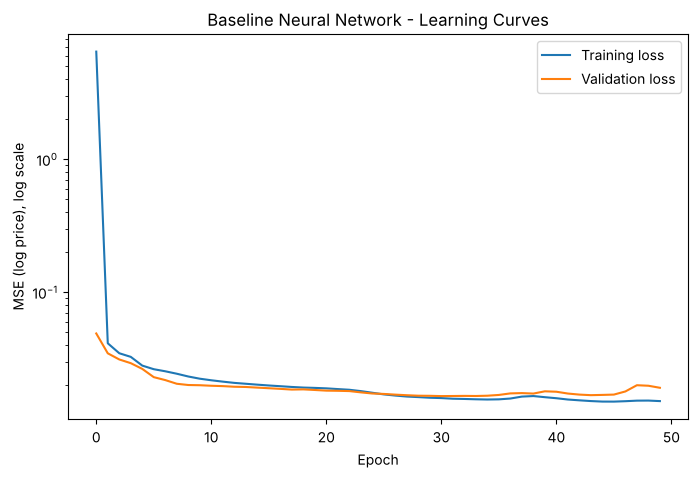

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (log price), log scale")
plt.yscale("log")
plt.title("Baseline Neural Network - Learning Curves")
plt.legend()
plt.show()

The y-axis uses a log scale so the whole curve is visible (the first epoch's loss is much larger than the rest). Both losses drop quickly in the first few epochs and level off by around epoch 25, so the network learns most of the pattern early. After about epoch 31, the validation loss stops improving and moves slightly above the training loss, with a bump around epoch 48. This is a sign of **mild overfitting** starting: the model keeps fitting the training data a little better without improving on new data. This motivates the later experiments with **regularization, Dropout and the number of epochs**.

In [36]:
# Generate predictions using the trained baseline neural network
baseline_pred = baseline_model.predict(X_val_p, verbose=0).flatten()

# Convert actual validation values into a NumPy array
y_true = np.asarray(y_val).flatten()

# Safety check: the targets and predictions must be finite numbers before evaluation
valid_mask = np.isfinite(y_true)
print("Missing/invalid target values:", (~valid_mask).sum())

if not np.isfinite(baseline_pred[valid_mask]).all():
    raise ValueError("Model predictions contain NaN or infinity. Check the model and input data.")

evaluate("Baseline NN", y_true[valid_mask], baseline_pred[valid_mask])

Missing/invalid target values: 0
Baseline NN
  MAE:  $115,781
  RMSE: $231,542
  R²:   0.967
  MAPE: 11.6%


In [37]:
results_df = pd.DataFrame(results).set_index("Model")
results_df.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.3f}", "MAPE (%)": "{:.1f}"})

,MAE,RMSE,R2,MAPE (%)
Model,,,,
Median predictor,"$760,202","$1,343,356",-0.116,143.4
Baseline NN,"$115,781","$231,542",0.967,11.6


The baseline neural network is far better than the median predictor on the validation set:
- **R² = 0.967**: the network explains about 97% of the variation in price, compared with none for the median predictor.
- **MAPE = 11.6%**: on average its prediction is about 12% away from the true price, compared with 143% for the median predictor.
- **MAE = \$115,781** compared with \$760,202, so the average error is about 85% smaller.

The RMSE (\$231,542) is about twice the MAE, which means some large errors remain, most likely on the most expensive properties. This baseline is the reference point for all the following experiments, which will try to improve it by changing the architecture, activation functions, learning rate, batch size and epochs, regularization and Dropout.

> **3.1 Building up to the baseline: how much does each step add?**

**Motivation:** the baseline network already reaches a MAPE of 11.6% (about 88% accuracy). To show *why*, we start from much simpler models and add our preparation steps one at a time, measuring the effect of each on the validation set.

**Description:** all neural networks below use the baseline design (Dense 64 → 32, ReLU, Adam 0.001, 50 epochs, batch 32, seed 42). Only the input data and target change. "Accuracy" here means 100% − MAPE.
- **Step 0:** linear regression on area and bedrooms only, as the simplest possible model.
- **Step 1:** neural network on the 13 numeric features as they are (no scaling), predicting the raw price in USD.
- **Step 2:** the same, with StandardScaler on the inputs.
- **Step 3:** the same, predicting log(price) instead of price.
- **Step 4:** adding the one-hot encoded categories (community, zone, property type…) and booleans. This is exactly the Baseline NN.
- **Steps 5–6:** the tuned final model (Section 5), on validation and test.

,MAPE (%),Accuracy ≈ (%),R2
Step,,,
0. Linear regression (area + bedrooms),79.4,20.6,0.414
"1. NN: numeric only, unscaled, raw price",53.5,46.5,0.624
2. + StandardScaler,46.8,53.2,0.719
3. + log(price) target,21.5,78.5,0.775
4. + one-hot categories = Baseline NN,11.6,88.4,0.967


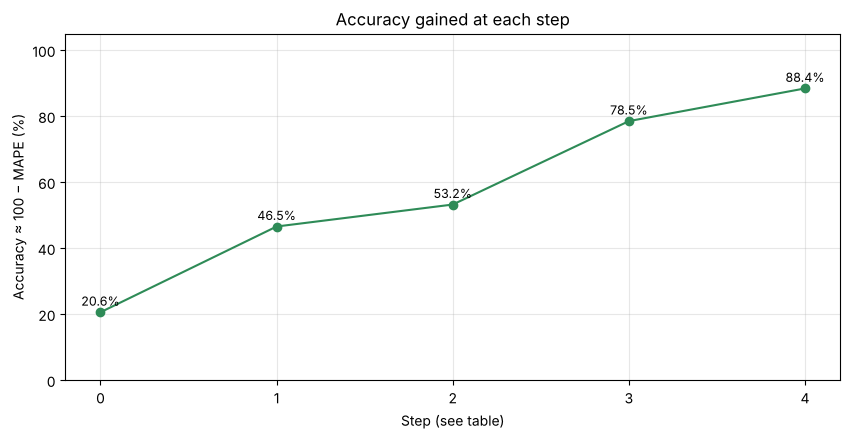

In [38]:
from sklearn.linear_model import LinearRegression

ladder = []
y_val_usd = np.exp(y_val.values)
y_train_usd = np.exp(y_train.values)

def ladder_add(step, pred_usd):
    p = np.ravel(pred_usd)
    mape = np.mean(np.abs(p - y_val_usd) / y_val_usd) * 100
    ladder.append({"Step": step, "MAPE (%)": mape, "Accuracy ≈ (%)": 100 - mape,
                   "R2": r2_score(y_val_usd, p)})

def ladder_from_results(step, name):
    r = pd.DataFrame(results).set_index("Model").loc[name]
    ladder.append({"Step": step, "MAPE (%)": r["MAPE (%)"], "Accuracy ≈ (%)": 100 - r["MAPE (%)"], "R2": r["R2"]})

def small_nn(X_a, X_b, target, log_target):
    """Same design as the baseline network; only the inputs/target change."""
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    m = keras.Sequential([layers.Input(shape=(X_a.shape[1],)),
                          layers.Dense(64, activation="relu"),
                          layers.Dense(32, activation="relu"),
                          layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    m.fit(X_a, target, epochs=50, batch_size=32, verbose=0)
    p = m.predict(X_b, verbose=0).ravel()
    return np.exp(p) if log_target else p

# Step 0: simplest model
basic = ["area_sqft", "bedrooms"]
ladder_add("0. Linear regression (area + bedrooms)",
           LinearRegression().fit(X_train[basic], y_train_usd).predict(X_val[basic]))

# Step 1: NN, numeric only, no scaling, raw price
Xa = X_train[num_cols].values.astype("float32")
Xb = X_val[num_cols].values.astype("float32")
ladder_add("1. NN: numeric only, unscaled, raw price", small_nn(Xa, Xb, y_train_usd, False))

# Step 2: + scaling
sc = StandardScaler().fit(X_train[num_cols])
Xa_s = sc.transform(X_train[num_cols]).astype("float32")
Xb_s = sc.transform(X_val[num_cols]).astype("float32")
ladder_add("2. + StandardScaler", small_nn(Xa_s, Xb_s, y_train_usd, False))

# Step 3: + log(price) target
ladder_add("3. + log(price) target", small_nn(Xa_s, Xb_s, y_train.values, True))

# Steps 4-6: already trained (taken from the results table)
ladder_from_results("4. + one-hot categories = Baseline NN", "Baseline NN")
if "Final A" in pd.DataFrame(results)["Model"].values:
    ladder_from_results("5. + tuning = Final A (validation)", "Final A")
if "TEST: Final A" in pd.DataFrame(results)["Model"].values:
    ladder_from_results("6. Final A (TEST)", "TEST: Final A")

ladder_df = pd.DataFrame(ladder).set_index("Step")
display(ladder_df.style.format({"MAPE (%)": "{:.1f}", "Accuracy ≈ (%)": "{:.1f}", "R2": "{:.3f}"}))

plt.figure(figsize=(10, 4.5))
plt.plot(range(len(ladder_df)), ladder_df["Accuracy ≈ (%)"].clip(lower=0), marker="o", color="seagreen")
for i, v in enumerate(ladder_df["Accuracy ≈ (%)"]):
    plt.text(i, max(v, 0) + 2, f"{v:.1f}%", ha="center", fontsize=9)
plt.xticks(range(len(ladder_df)), [s.split(".")[0] for s in ladder_df.index])
plt.xlabel("Step (see table)")
plt.ylabel("Accuracy ≈ 100 − MAPE (%)")
plt.ylim(0, 105)
plt.title("Accuracy gained at each step")
plt.grid(alpha=0.3)
plt.show()

**Results**

| Step | Change | MAPE | ≈ Accuracy | R² | Gain |
|---|---|---|---|---|---|
| 0 | Linear regression, area + bedrooms only | 79.4% | 20.6% | 0.414 | – |
| 1 | Neural network, 13 numeric features, unscaled, raw price | 53.5% | 46.5% | 0.624 | +25.9 |
| 2 | + StandardScaler on the inputs | 46.8% | 53.2% | 0.719 | +6.7 |
| 3 | + log(price) as the target | 21.5% | 78.5% | 0.775 | +25.3 |
| 4 | + one-hot categories and booleans (= Baseline NN) | 11.6% | 88.4% | 0.967 | +9.9 |
| 5 | + tuning (sigmoid + early stopping) = Final A, validation | 8.9% | 91.1% | 0.980 | +2.7 |
| 6 | Final A on the test set | 8.8% | 91.2% | 0.980 | +0.1 |

Steps 0–3 were trained in the cell above. Steps 4–6 come from the results table (Sections 3 and 5). When the notebook runs from top to bottom, the cell above shows steps 0–4 only, because Final A is trained later, in Section 5; steps 5–6 in this table are taken from Section 5.

**Interpretation**

- **Step 0 → 1 (+25.9 points):** a simple straight-line model on two features is far from enough (20.6%). The first neural network more than doubled the accuracy to 46.5%. This step changed two things at once: the model became non-linear, and it used all 13 numeric features instead of two. The gain therefore comes from both, not from the network alone.
- **Step 1 → 2 (+6.7 points):** scaling helped, but less than expected. The Adam optimizer adapts its step size for each weight, which partly compensates for inputs on very different scales (area in the thousands, bedrooms 0–6). Scaling still made training more stable and raised R² from 0.624 to 0.719.
- **Step 2 → 3 (+25.3 points):** training on log(price) was the single biggest step for MAPE, which fell from 46.8% to 21.5%. With raw prices, the MSE loss is dominated by the most expensive properties: a \$100,000 error on a \$10M villa counts the same as a \$100,000 error on a \$150,000 studio. The network therefore learns to get luxury prices roughly right in dollars, while making very large percentage errors on cheaper properties. On a log scale, errors become relative, so every property counts equally. R² rose much less (0.719 → 0.775), because R² is measured in dollars, where the expensive properties still dominate.
- **Step 3 → 4 (+9.9 points):** adding the categorical features (community, zone, property type, view, furnishing…) gave the largest jump in R², from 0.775 to 0.967. This confirms the EDA finding that **location** drives price: median prices range from about \$115K in International City to about \$3.5M in Emirates Hills, and the numeric features alone cannot capture this.
- **Step 4 → 5 (+2.7 points):** hyperparameter tuning (Section 4) added a smaller but real improvement, larger than the seed variation measured in 4.2.
- **Step 5 → 6:** the test score matches the validation score, so the final accuracy holds on new data.

**Conclusion:** most of the accuracy came from **preparing the data correctly**: the accuracy rose from 20.6% to 88.4% before any tuning. Tuning the network's hyperparameters then added the last 2.8 points. The biggest single improvements came from choosing the right target scale (log price) and the right features (location and property type), not from making the network bigger.



# **4. Experiments**

In this section we run controlled experiments to find out which settings improve the neural network. The baseline network from Section 3 is the reference point.

**Rules used for every experiment (so the results are comparable):**
1. Every experiment starts from the baseline (Dense 64 → 32, ReLU, Adam with learning rate 0.001, 50 epochs, batch size 32) and changes **only one thing**.
2. All experiments use the same prepared data (`X_train_p`, `y_train`, `X_val_p`, `y_val`) and the same random seed (42), so differences come from the setting we changed and not from luck in the starting weights.
3. Every model is evaluated on the **validation set** with the same `evaluate()` function (MAE, RMSE, R² and MAPE in USD). The **test set is not used** until the final model in Section 5.
4. Models are compared mainly on **validation MAPE**. The network is trained on log(price), and MAPE measures the average error as a percentage of the price, so cheap and expensive properties count equally. MAE, RMSE and R² are reported as well.

> **4.0 Experiment toolkit**

The cell below defines `run_experiment(...)`. Its default values are the baseline settings, so each call only lists the one thing that changes. For every run it: resets the random seed, builds the network, trains it, evaluates it on the validation set with `evaluate()`, stores the learning curves, and saves all results to `experiment_log.json` (a backup in case Colab disconnects). It also defines `show()` (results table) and `plot_curves()` (learning curves).

In [39]:
import time, json, os

histories = {}   # run name -> learning curves (loss, val_loss, mae, val_mae for every epoch)
run_info = {}    # run name -> extra facts (epochs actually run, best epoch, training time)
LOG_FILE = "experiment_log.json"


def make_optimizer(name, lr):
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=lr)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr)
    if name == "sgd_momentum":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    raise ValueError("Unknown optimizer: " + name)


def build_model(hidden=(64, 32), activation="relu", dropout=0.0, l2=0.0,
                optimizer="adam", lr=0.001):
    """Same design as the baseline: hidden layers -> 1 linear output neuron."""
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden:
        if activation == "leaky_relu":
            model.add(layers.Dense(units, kernel_regularizer=reg))
            model.add(layers.LeakyReLU())
        else:
            model.add(layers.Dense(units, activation=activation, kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    model.compile(optimizer=make_optimizer(optimizer, lr), loss="mse", metrics=["mae"])
    return model


def save_log():
    """Saves every result so far, so a Colab disconnect does not lose hours of work."""
    with open(LOG_FILE, "w") as f:
        json.dump({"results": results, "histories": histories, "run_info": run_info}, f)


def run_experiment(name, hidden=(64, 32), activation="relu", optimizer="adam", lr=0.001,
                   batch_size=32, epochs=50, dropout=0.0, l2=0.0,
                   early_stopping=False, patience=10, seed=SEED):
    """Trains one model and adds it to the results table.
    Every default below is the BASELINE setting, so a call only lists what it changes."""
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)          # identical starting point for every run

    model = build_model(hidden, activation, dropout, l2, optimizer, lr)

    callbacks = []
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True))

    start = time.time()
    history = model.fit(X_train_p, y_train,
                        validation_data=(X_val_p, y_val),
                        epochs=epochs, batch_size=batch_size,
                        callbacks=callbacks, verbose=0)
    seconds = time.time() - start

    results[:] = [r for r in results if r["Model"] != name]   # re-running a cell replaces its row
    evaluate(name, y_val, model.predict(X_val_p, verbose=0))

    val_curve = history.history["val_loss"]
    histories[name] = history.history
    run_info[name] = {
        "epochs_run": len(val_curve),
        "best_epoch": int(np.argmin(val_curve)) + 1,
        "train_mae": float(history.history["mae"][-1]),
        "val_mae": float(history.history["val_mae"][-1]),
        "seconds": round(seconds),
    }
    print(f"  trained {len(val_curve)} epochs in {seconds:.0f} s\n")
    save_log()
    return model


def group(prefix):
    """The baseline plus every run whose name starts with `prefix`."""
    return ["Baseline NN"] + [n for n in histories if n.startswith(prefix) and n != "Baseline NN"]


def plot_curves(names, title, metric="loss"):
    """metric='loss' plots MSE; metric='mae' plots the mean absolute error (both on log(price))."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for n in names:
        axes[0].plot(histories[n][metric], label=n)
        axes[1].plot(histories[n]["val_" + metric], label=n)
    axes[0].set_title("Training " + metric)
    axes[1].set_title("Validation " + metric)
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.set_yscale("log")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(("MSE" if metric == "loss" else "MAE") + " on log(price), log scale")
    axes[1].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def show(prefix=None, sort=False):
    """Results table. show('Arch:') = baseline + architecture runs; show() = everything."""
    table = pd.DataFrame(results).set_index("Model").join(pd.DataFrame(run_info).T)
    if prefix is not None:
        keep = [m for m in table.index if m == "Baseline NN" or m.startswith(prefix)]
        table = table.loc[keep]
    if sort:
        table = table.sort_values("MAPE (%)")
    formats = {"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.3f}", "MAPE (%)": "{:.1f}",
               "epochs_run": "{:.0f}", "best_epoch": "{:.0f}", "seconds": "{:.0f}",
               "train_mae": "{:.4f}", "val_mae": "{:.4f}"}
    formats = {c: f for c, f in formats.items() if c in table.columns}
    return (table.style.format(formats, na_rep="-")
                 .highlight_min(subset=["MAE", "RMSE", "MAPE (%)"], color="#c6efce")
                 .highlight_max(subset=["R2"], color="#c6efce"))

**Sanity check before the experiments.** Before running many long experiments, we confirm that the data going into the network contains no NaN values, and we train for 2 epochs with live output to make sure the loss stays a normal number (a NaN loss would mean the inputs or the learning setup are broken).

In [40]:
# 1. Is there NaN in the data going into the network?
print("NaN in X_train_p:", int(np.isnan(X_train_p).sum()), "| X_val_p:", int(np.isnan(X_val_p).sum()))
print("NaN in y_train:", int(y_train.isna().sum()), "| y_val:", int(y_val.isna().sum()))
bad = pd.Series(np.isnan(X_train_p).sum(axis=0), index=preprocessor.get_feature_names_out())
print(bad[bad > 0])

# 2. Does the loss become nan during training? (2 quick epochs, shown live)
test_model = build_model()
test_model.fit(X_train_p, y_train, epochs=2, batch_size=32, verbose=1)

NaN in X_train_p: 0 | X_val_p: 0
NaN in y_train: 0 | y_val: 0
Series([], dtype: int64)
Epoch 1/2


   1/1094 ━━━━━━━━━━━━━━━━━━━━ 16:26 902ms/step - loss: 165.0659 - mae: 12.7909

  19/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 152.3730 - mae: 12.2923     

  34/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 142.3472 - mae: 11.8512

  48/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 131.6034 - mae: 11.3104

...

1035/1094 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0563 - mae: 0.1866

1050/1094 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0562 - mae: 0.1864

1068/1094 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0561 - mae: 0.1862

1089/1094 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0560 - mae: 0.1860

1094/1094 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0492 - mae: 0.1737


> **4.1 Reference baseline**

We train the baseline once more through the toolkit (same settings, same seed). This stores its learning curves for the comparisons below. It replaces the "Baseline NN" row from Section 3 with identical numbers.

In [41]:
baseline_ref = run_experiment("Baseline NN")
show()

Baseline NN
  MAE:  $115,781
  RMSE: $231,542
  R²:   0.967
  MAPE: 11.6%
  trained 50 epochs in 194 s



,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Median predictor,"$760,202","$1,343,356",-0.116,143.4,-,-,-,-,-
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194


> **4.2 Run-to-run variation (random seed)**

**Motivation:** even with identical settings, a different random starting point gives slightly different results. Before comparing settings, we measure how large this natural variation is. A difference between two experiments that is smaller than this variation is probably just noise.

**Description:** the baseline settings are trained three more times with seeds 1, 2 and 3. Only the random starting weights and the order in which the training rows are shuffled change.

In [42]:
for s in (1, 2, 3):
    run_experiment(f"Seed: {s}", seed=s)

seed_runs = ["Baseline NN"] + [n for n in histories if n.startswith("Seed:")]
seed_mape = pd.DataFrame(results).set_index("Model").loc[seed_runs, "MAPE (%)"]
print(f"Validation MAPE over {len(seed_mape)} seeds: mean {seed_mape.mean():.2f}%, "
      f"std {seed_mape.std():.2f}%, min {seed_mape.min():.2f}%, max {seed_mape.max():.2f}%")
show("Seed:")

Seed: 1
  MAE:  $143,262
  RMSE: $286,532
  R²:   0.949
  MAPE: 14.8%
  trained 50 epochs in 180 s



Seed: 2
  MAE:  $111,236
  RMSE: $241,347
  R²:   0.964
  MAPE: 11.0%
  trained 50 epochs in 167 s



Seed: 3
  MAE:  $106,220
  RMSE: $234,319
  R²:   0.966
  MAPE: 11.0%
  trained 50 epochs in 158 s

Validation MAPE over 4 seeds: mean 12.09%, std 1.81%, min 10.98%, max 14.77%


,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Seed: 1,"$143,262","$286,532",0.949,14.8,50,29,0.1001,0.1351,180
Seed: 2,"$111,236","$241,347",0.964,11.0,50,42,0.0938,0.1130,167
Seed: 3,"$106,220","$234,319",0.966,11.0,50,45,0.0967,0.1068,158


**Results**

Four runs with identical settings (seeds 42, 1, 2 and 3) gave a validation MAPE between 11.0% and 14.8% (mean 12.1%, standard deviation 1.8 percentage points) and an R² between 0.949 and 0.967. MAE ranged from \$106,220 to \$143,262 and RMSE from \$231,542 to \$286,532. Seed 1 was clearly the worst run (MAPE 14.8%, R² 0.949), while the other three were close together (MAPE 11.0% to 11.6%).

**Interpretation**

Changing only the random starting weights and the shuffling order moved MAPE by up to 3.8 percentage points. So the run-to-run variation is not negligible. In the experiments below, a difference smaller than about 1 to 2 points of MAPE (or about 0.01 of R²) is not treated as evidence that a setting is better, and as the bar for a real improvement we use the best seed run (11.0%). As the typical reference we use the mean of the four runs (12.1%) rather than the single baseline run (11.6%).

The table suggests a possible cause. The best epoch differs a lot between runs (29 to 45). Seed 1 reached its lowest validation loss at epoch 29; after about epoch 43 its validation loss rose sharply, and it finished at epoch 50 with the worst score. This fits the unstable late-epoch validation curve we saw in the baseline, and it motivates the early stopping experiment in 4.8. Each later experiment is a single run, so its conclusions are stated with caution.

> **4.3 Experiment: network architecture**

**Motivation:** find out whether the baseline network is too small (underfitting) or whether a bigger network is better or starts to overfit.

**Description:** only the hidden layers change; everything else is the baseline (ReLU, Adam 0.001, batch 32, 50 epochs). We try one small layer (32), the baseline (64→32), three layers (128→64→32) and a larger three-layer network (256→128→64), which covers both fewer and more layers and neurons.

Arch: 32
  MAE:  $104,290
  RMSE: $212,408
  R²:   0.972
  MAPE: 10.5%
  trained 50 epochs in 152 s



Arch: 128-64-32
  MAE:  $115,376
  RMSE: $237,144
  R²:   0.965
  MAPE: 11.5%
  trained 50 epochs in 185 s



Arch: 256-128-64
  MAE:  $157,632
  RMSE: $334,863
  R²:   0.931
  MAPE: 15.1%
  trained 50 epochs in 207 s



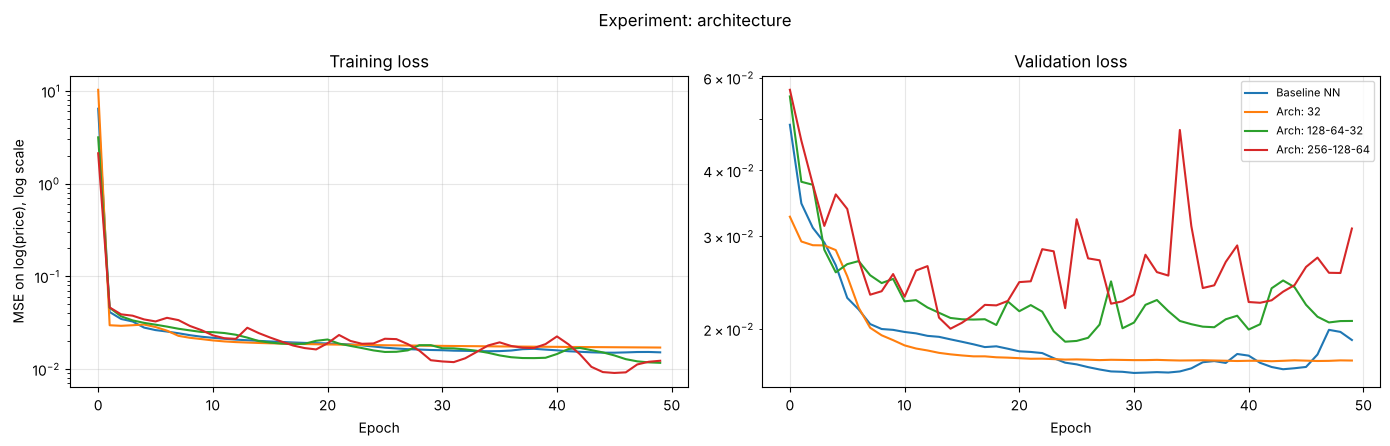

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Arch: 32,"$104,290","$212,408",0.972,10.5,50,43,0.1035,0.1042,152
Arch: 128-64-32,"$115,376","$237,144",0.965,11.5,50,25,0.0855,0.1142,185
Arch: 256-128-64,"$157,632","$334,863",0.931,15.1,50,15,0.0876,0.1399,207


In [43]:
run_experiment("Arch: 32",         hidden=(32,))
run_experiment("Arch: 128-64-32",  hidden=(128, 64, 32))
run_experiment("Arch: 256-128-64", hidden=(256, 128, 64))

plot_curves(group("Arch:"), "Experiment: architecture")
show("Arch:")

**Results**

Compared with the baseline (64→32, MAPE 11.6%, R² 0.967), the smallest network did best. The single 32-neuron layer gave MAPE 10.5%, MAE \$104,290, RMSE \$212,408 and R² 0.972, and it trained fastest (152 s).

The two larger networks behaved differently:

- 128→64→32 gave MAPE 11.5%, MAE \$115,376, RMSE \$237,144 and R² 0.965, almost the same as the baseline.
- 256→128→64 had the highest error: MAPE 15.1%, MAE \$157,632, RMSE \$334,863 and R² 0.931, and took the longest (207 s).

The training loss curves of all four networks end at a similar level, with the two larger networks slightly lower. The validation curves are very different. The 32-neuron network’s validation loss falls smoothly and stays flat after about epoch 15. The 256→128→64 network’s validation loss is very unstable, with large spikes, the biggest close to 0.05 at epoch 35, and it rises again at the end. The 128→64→32 network also spikes (around epochs 29 and 43–45) and ends above the baseline. The larger networks reached their best validation loss much earlier (epochs 25 and 15, compared with 31 for the baseline and 43 for the 32-neuron network).

**Interpretation**

The larger networks overfit. Their training error is lower than the baseline’s (train_mae 0.086 and 0.088 against 0.098), but their validation error is higher (0.114 and 0.140). The gap between training and validation MAE is about 0.03 for 128→64→32 and 0.05 for 256→128→64, compared with 0.012 for the baseline and almost zero for the 32-neuron network. With more weights, they learn details of the training data that don’t carry over to new properties. Their early best epochs and jumpy validation curves fit this explanation.

The 256→128→64 network (MAPE 15.1%) is above the whole baseline seed range from 4.2 (11.0% to 14.8%), and its R² (0.931) is below all four baseline seeds (0.949 to 0.967), so it is genuinely worse. The 128→64→32 network’s scores lie inside the seed range, so on accuracy alone it is not clearly different from the baseline, but its curve shows the same overfitting pattern. Part of these scores comes from where training happened to stop: the score is taken at epoch 50, which can land on a spike. Early stopping would partly reduce this, but it would not fix the underlying overfitting.

The data does not need a large network. The 32-neuron network’s 10.5% is 0.5 points below the best baseline seed, so a single run is not enough to call it better. We therefore checked it with more seeds in 4.3b.

In [44]:
# GOAL: check whether the 32-neuron network is really better than the baseline (64→32),
# or whether its better score (10.5% vs 11.1% MAPE) is just luck from one random seed.

# 1) Train the 32-neuron network three more times, each with a different random seed.
#    Only the random starting weights and the shuffling order change; everything else
#    (data, ReLU, Adam 0.001, batch 32, 50 epochs) stays the same as in the baseline.
for s in (1, 2, 3):
    run_experiment(f"Seeds-32: {s}", hidden=(32,), seed=s)
    # The name starts with "Seeds-32:" (not "Seed:"), so these runs do NOT get mixed into
    # the seed statistics of section 4.2 or into the architecture table of section 4.3.

# 2) Show everything in one table:
#    "Seed:"      = baseline 64→32 with seeds 1, 2, 3 (plus "Baseline NN" = seed 42, always shown)
#    "Arch: 32"   = the 32-neuron network with seed 42 (from the architecture experiment)
#    "Seeds-32:"  = the 32-neuron network with seeds 1, 2, 3 (the runs from step 1)
show(("Seed:", "Seeds-32:", "Arch: 32"))

Seeds-32: 1
  MAE:  $110,386
  RMSE: $224,907
  R²:   0.969
  MAPE: 10.5%
  trained 50 epochs in 144 s



Seeds-32: 2
  MAE:  $98,119
  RMSE: $200,094
  R²:   0.975
  MAPE: 10.0%
  trained 50 epochs in 142 s



Seeds-32: 3
  MAE:  $105,699
  RMSE: $217,660
  R²:   0.971
  MAPE: 10.2%
  trained 50 epochs in 146 s



,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Seed: 1,"$143,262","$286,532",0.949,14.8,50,29,0.1001,0.1351,180
Seed: 2,"$111,236","$241,347",0.964,11.0,50,42,0.0938,0.1130,167
Seed: 3,"$106,220","$234,319",0.966,11.0,50,45,0.0967,0.1068,158
Arch: 32,"$104,290","$212,408",0.972,10.5,50,43,0.1035,0.1042,152
Seeds-32: 1,"$110,386","$224,907",0.969,10.5,50,15,0.0956,0.1088,144
Seeds-32: 2,"$98,119","$200,094",0.975,10.0,50,50,0.0947,0.0999,142
Seeds-32: 3,"$105,699","$217,660",0.971,10.2,50,50,0.0989,0.1038,146


> **4.3b Follow-up: is the 32-neuron network really better?**

**Motivation**: In 4.3 the 32-neuron network beat the baseline (MAPE 10.5% vs 11.6%), but 4.2 showed that one run can vary by more than that. We repeated the comparison with several random seeds.

**Description**: Both networks (32 neurons, and the baseline 64→32; ReLU, Adam 0.001, batch 32, 50 epochs) were trained with seeds 42, 1, 2 and 3. Only the seed changes.

**Results**: The 32-neuron network had a validation MAPE of 10.0–10.5% (mean 10.3%), against 11.0–14.8% (mean 12.1%) for the baseline. Every 32-neuron run beat every baseline run on MAPE. Mean R² was 0.972 against 0.962.

**Interpretation**: The 32-neuron network is better by about 1.8 points of MAPE on average and is more consistent across seeds, so the gain is not just luck. The ranges of MAE, RMSE and R² overlap between the two groups, so the gain in those metrics is smaller. With four runs per network and no statistical test, this is strong evidence, not proof. The test set in Section 5 gives the fair check.

> **4.4 Experiment: activation functions**

**Motivation:** the activation function decides how each hidden neuron transforms its input. ReLU is the usual choice. Tanh and sigmoid squash values into a small range and can learn slowly when they saturate. LeakyReLU is like ReLU but lets a small negative signal through, which avoids "dead" neurons.

**Description:** only the activation of the hidden layers changes (the output layer stays linear). We compare ReLU (baseline), tanh, sigmoid and LeakyReLU (Keras default slope).

Act: tanh
  MAE:  $103,666
  RMSE: $231,474
  R²:   0.967
  MAPE: 10.0%
  trained 50 epochs in 173 s



Act: sigmoid
  MAE:  $91,443
  RMSE: $185,947
  R²:   0.979
  MAPE: 9.2%
  trained 50 epochs in 162 s



Act: leaky_relu
  MAE:  $103,169
  RMSE: $203,918
  R²:   0.974
  MAPE: 10.3%
  trained 50 epochs in 169 s



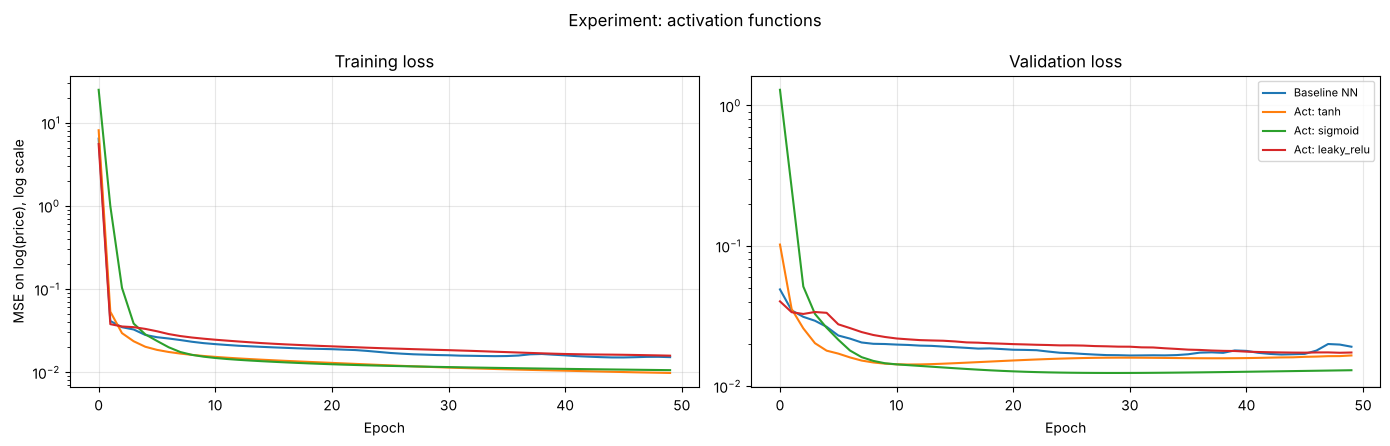

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Act: tanh,"$103,666","$231,474",0.967,10.0,50,12,0.0787,0.1008,173
Act: sigmoid,"$91,443","$185,947",0.979,9.2,50,30,0.0820,0.0901,162
Act: leaky_relu,"$103,169","$203,918",0.974,10.3,50,49,0.1001,0.1045,169


In [45]:
run_experiment("Act: tanh",       activation="tanh")
run_experiment("Act: sigmoid",    activation="sigmoid")
run_experiment("Act: leaky_relu", activation="leaky_relu")

plot_curves(group("Act:"), "Experiment: activation functions")
show("Act:")

**Results**

Compared with the ReLU baseline (MAPE 11.6%, R² 0.967), sigmoid had the lowest error: MAPE 9.2%, MAE \$91,443, RMSE \$185,947 and R² 0.979. Tanh (MAPE 10.0%) and LeakyReLU (MAPE 10.3%) were also better than the baseline on MAPE and MAE. Training time was similar for all four (162 to 194 s). In the curves, sigmoid started with the highest loss, but after about 10 epochs it had the lowest and flattest validation loss. Tanh reached its best validation loss early (epoch 12) and then drifted slightly upward.

**Interpretation**

Sigmoid is the best activation here. Its MAPE is 1.8 points below the best of the four baseline seeds (11.0%), so the gain is larger than random seed variation. Tanh and LeakyReLU are only 0.7 to 1.0 points below that value, so we treat them as slightly better but not clearly different. Tanh also had the same RMSE as the baseline (\$231,474 vs \$231,542) despite its lower MAPE, which suggests it handles typical properties well but makes larger errors on expensive ones. Its gap between training and validation MAE (0.079 vs 0.101) is the largest of the four, which fits its early best epoch and a tendency to overfit. Sigmoid is usually expected to be the weakest hidden activation because of vanishing gradients, but that problem mostly affects deep networks, and this one has only two hidden layers. Each activation was trained once, so these conclusions are tentative.

> **4.5 Experiment: learning rate**

**Motivation:** the learning rate controls how big each weight update is. Too large and training becomes unstable or diverges; too small and it learns very slowly.

**Description:** only the Adam learning rate changes: 0.1, 0.01, 0.001 (baseline) and 0.0001.

LR: 0.1
  MAE:  $136,933
  RMSE: $323,476
  R²:   0.935
  MAPE: 14.2%
  trained 50 epochs in 159 s



LR: 0.01
  MAE:  $118,075
  RMSE: $421,613
  R²:   0.890
  MAPE: 11.5%
  trained 50 epochs in 183 s



LR: 0.0001
  MAE:  $97,882
  RMSE: $196,245
  R²:   0.976
  MAPE: 10.1%
  trained 50 epochs in 177 s



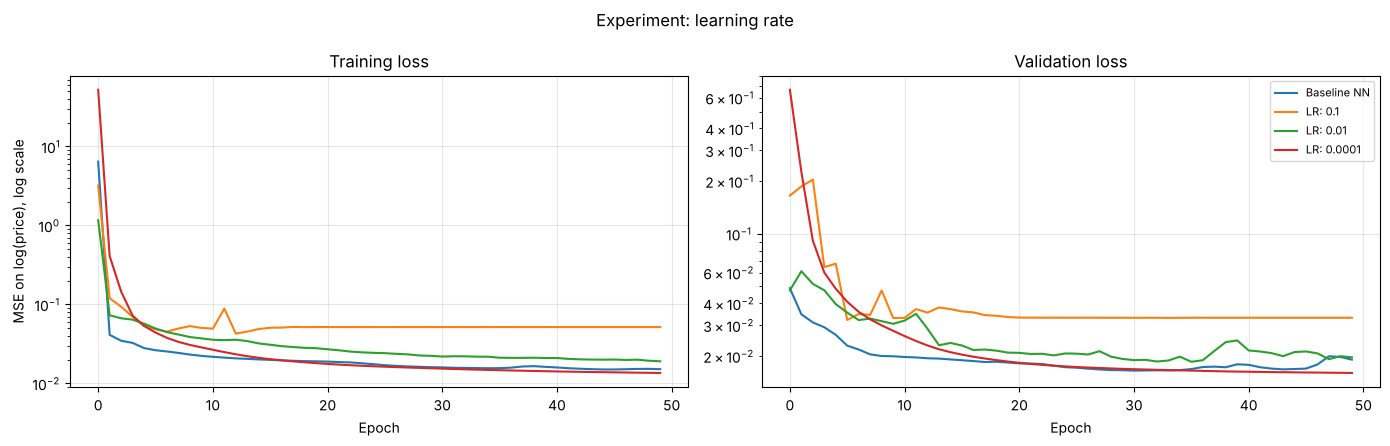

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
LR: 0.1,"$136,933","$323,476",0.935,14.2,50,6,0.1743,0.1424,159
LR: 0.01,"$118,075","$421,613",0.890,11.5,50,36,0.1091,0.1095,183
LR: 0.0001,"$97,882","$196,245",0.976,10.1,50,50,0.0923,0.1002,177


In [46]:
run_experiment("LR: 0.1",    lr=0.1)
run_experiment("LR: 0.01",   lr=0.01)
run_experiment("LR: 0.0001", lr=0.0001)

plot_curves(group("LR:"), "Experiment: learning rate")
show("LR:")

**Results**

Compared with the baseline (learning rate 0.001, MAPE 11.6%, R² 0.967), the smallest learning rate was best. LR 0.0001 gave MAPE 10.1%, MAE \$97,882, RMSE \$196,245 and R² 0.976. LR 0.01 had a similar MAPE (11.5%) but clearly worse RMSE (\$421,613) and R² (0.890). LR 0.1 was the worst: MAPE 14.2%, MAE \$136,933, RMSE \$323,476 and R² 0.935. In the curves, LR 0.1 was erratic in the first 15 epochs and then stopped improving: from about epoch 20 its training and validation loss stayed flat, well above every other run (best validation epoch 6). LR 0.01 had a noisy validation loss in the first 15 epochs and another bump around epochs 38 to 40, while LR 0.0001 started highest but decreased smoothly and was still falling at epoch 50 (best epoch 50). Training times were similar (159 to 194 s).

**Interpretation**

A learning rate of 0.1 is too large: the first updates overshoot, and the network then gets stuck on a plateau. Its training error (0.174) is the highest of all runs without Dropout, so it cannot even fit the training data well. A likely explanation is that the large early steps pushed many ReLU neurons into a state where they output zero for every property and stop learning, which leaves the network with less capacity. Its MAPE (14.2%) is near the top of the baseline seed range from 4.2, but its R² (0.935) is below all four baseline runs (0.949 to 0.967), so it is genuinely worse. This setting is also very unstable from run to run: in an earlier run of this notebook it collapsed completely to a near-constant prediction (MAPE about 147%). LR 0.01 did not fail, but its R² (0.890) is below all four baseline runs, so it is genuinely worse, probably because of larger errors on expensive properties. LR 0.0001 reached MAPE 10.1%, which is 0.9 points below the best baseline seed (11.0%), so it is probably a real but modest improvement. Because its curve was still falling at epoch 50, it may improve further with more epochs, which we test in 4.8. Each learning rate was trained once, so these conclusions are tentative.

> **4.6 Experiment: optimizers**

**Motivation:** the optimizer decides how the weights are updated from the gradients. We compare plain gradient descent (SGD), SGD with momentum, RMSprop and Adam.

**Description:** only the optimizer changes. Each optimizer uses its usual default learning rate (SGD 0.01, SGD with momentum 0.9 at 0.01, RMSprop 0.001, Adam 0.001), because the best learning rate is different for each one.

Opt: SGD
  MAE:  $96,898
  RMSE: $198,733
  R²:   0.976
  MAPE: 10.0%
  trained 50 epochs in 156 s



Opt: SGD+momentum
  MAE:  $95,912
  RMSE: $214,089
  R²:   0.972
  MAPE: 9.2%
  trained 50 epochs in 163 s



Opt: RMSprop
  MAE:  $122,101
  RMSE: $247,545
  R²:   0.962
  MAPE: 11.4%
  trained 50 epochs in 165 s



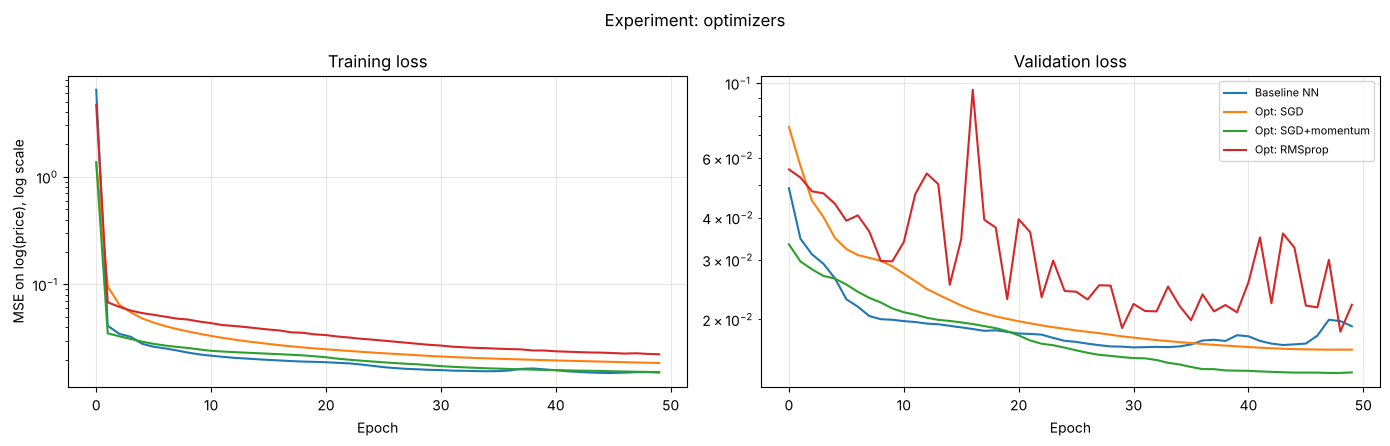

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Opt: SGD,"$96,898","$198,733",0.976,10.0,50,48,0.1082,0.1002,156
Opt: SGD+momentum,"$95,912","$214,089",0.972,9.2,50,48,0.0980,0.0931,163
Opt: RMSprop,"$122,101","$247,545",0.962,11.4,50,49,0.1188,0.1183,165


In [47]:
run_experiment("Opt: SGD",          optimizer="sgd",          lr=0.01)
run_experiment("Opt: SGD+momentum", optimizer="sgd_momentum", lr=0.01)
run_experiment("Opt: RMSprop",      optimizer="rmsprop",      lr=0.001)

plot_curves(group("Opt:"), "Experiment: optimizers")
show("Opt:")

**Results**

Compared with the Adam baseline (MAPE 11.6%, R² 0.967), SGD with momentum had the lowest MAPE (9.2%) and MAE (\$95,912). Plain SGD had MAPE 10.0%, the lowest RMSE (\$198,733) and the highest R² (0.976). RMSprop was the weakest (MAPE 11.4%, MAE \$122,101, R² 0.962). Training times were similar (156 to 165 s). In the curves, SGD and SGD with momentum decreased smoothly and were still improving at epoch 50 (best epoch 48 for both). RMSprop’s validation loss was very jumpy, with a spike to almost 0.1 at epoch 17, and stayed above the others; it also had the highest training error (0.119).

**Interpretation**

SGD with momentum is the best optimizer here. Its MAPE is 1.8 points below the best baseline seed (11.0% in 4.2), so the gain is larger than random seed variation. Plain SGD (10.0%) is 1.0 point below that value, so it is better but less clearly so. RMSprop (11.4%) lies inside the baseline seed range (11.0% to 14.8%), so it is not clearly different from Adam. Momentum has the best MAPE and MAE but a higher RMSE than plain SGD (\$214,089 vs \$198,733), which suggests it makes somewhat larger errors on expensive properties. The gentler optimizers (SGD, SGD with momentum) learned more slowly but more smoothly and ended with a smaller gap between training and validation error than Adam. This matches the learning rate result in 4.5, where a smaller Adam learning rate (0.0001) also helped. A possible reason is that Adam at 0.001 learns fast but then becomes noisy and slightly overfits, while RMSprop adapts its step sizes without momentum smoothing, which may explain its spikes. Each optimizer used its own usual default learning rate and was trained once, so these conclusions are tentative.

> **4.7 Experiment: batch size**

**Motivation:** the batch size is the number of training rows used for each weight update. Small batches give more (but noisier) updates per epoch and take longer; large batches give fewer, smoother updates and run faster.

**Description:** only the batch size changes: 16, 32 (baseline), 64 and 128, with 50 epochs each.

Batch: 16
  MAE:  $108,405
  RMSE: $225,715
  R²:   0.969
  MAPE: 10.6%
  trained 50 epochs in 319 s



Batch: 64
  MAE:  $106,161
  RMSE: $215,951
  R²:   0.971
  MAPE: 10.4%
  trained 50 epochs in 99 s



Batch: 128
  MAE:  $112,215
  RMSE: $237,958
  R²:   0.965
  MAPE: 10.5%
  trained 50 epochs in 52 s



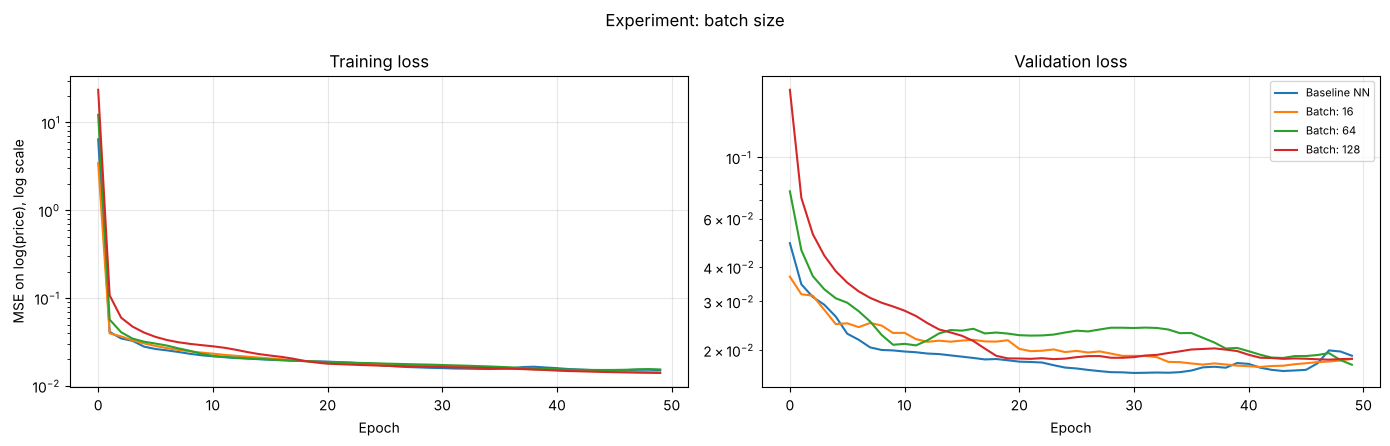

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Batch: 16,"$108,405","$225,715",0.969,10.6,50,42,0.0945,0.1067,319
Batch: 64,"$106,161","$215,951",0.971,10.4,50,50,0.0988,0.1058,99
Batch: 128,"$112,215","$237,958",0.965,10.5,50,48,0.0944,0.1085,52


In [48]:
run_experiment("Batch: 16",  batch_size=16)
run_experiment("Batch: 64",  batch_size=64)
run_experiment("Batch: 128", batch_size=128)

plot_curves(group("Batch:"), "Experiment: batch size")
show("Batch:")

**Results**

All three batch sizes gave a slightly lower MAPE than the baseline (batch 32, MAPE 11.6%, R² 0.967):

- batch 16: 10.6%, R² 0.969, MAE \$108,405, RMSE \$225,715
- batch 64: 10.4%, R² 0.971, MAE \$106,161, RMSE \$215,951
- batch 128: 10.5%, R² 0.965, MAE \$112,215, RMSE \$237,958

All three also had a lower MAE than the baseline (\$115,781). Batches 16 and 64 also improved RMSE and R², while batch 128 had a slightly higher RMSE and lower R².

The biggest difference was training time. Batch 16 took 319 s, about 1.6 times as long as the baseline (194 s), while batch 64 took 99 s and batch 128 only 52 s, about 3.7 times faster than the baseline.

In the curves, batch 128 started with the highest loss and decreased more slowly in the first 15 to 20 epochs, but smoothly. Batch 64’s validation loss stayed above the others between about epochs 13 and 37 before falling. Batch 16 stayed close to the baseline. Batch 64 and batch 128 reached their best validation loss at the very end (epochs 50 and 48), while the baseline’s validation loss rose again around epoch 48.

**Interpretation**

Batch size had no clear effect on accuracy. All three MAPE values (10.4% to 10.6%) are only 0.4 to 0.6 points below the best baseline seed (11.0%), and the R² values (0.965 to 0.971) are within or only just above the seed range from 4.2 (0.949 to 0.967). The differences are therefore within run-to-run variation.

The effect on speed is large. With 35,000 training rows:

- batch 16 makes about 2,188 weight updates per epoch
- batch 32 makes about 1,094
- batch 128 makes only about 274

Smaller batches give more frequent but noisier updates and take longer. Larger batches use the hardware more efficiently and run faster. Because batches 64 and 128 make fewer updates, they learn more slowly per epoch. Their late best epochs suggest they were still improving at epoch 50 and might gain from more epochs.

We kept batch size 32 for the remaining experiments, so that all results stay comparable with the baseline, since no batch size was clearly more accurate. For a larger dataset or a time limit, batch 128 would be a sensible choice: it gives similar accuracy at about a quarter of the training time. Each batch size was trained once, so these conclusions are tentative.

> **4.8 Experiment: number of epochs and early stopping**

**Motivation:** in the baseline the validation loss stopped improving around epoch 31 and then became unstable, so 50 epochs may be too many. Early stopping stops training automatically when the validation loss stops improving and returns the weights of the best epoch.

**Description:** we train the baseline for 20 and for 100 epochs, and for up to 100 epochs with early stopping (patience 10: stop if the validation loss has not improved for 10 epochs, then restore the best weights). Note: early stopping uses the validation set to choose the stopping point, so its validation score is slightly optimistic; the test set in Section 5 gives the fair number.

Epochs: 20
  MAE:  $106,216
  RMSE: $213,240
  R²:   0.972
  MAPE: 10.9%
  trained 20 epochs in 68 s



Epochs: 100
  MAE:  $106,829
  RMSE: $224,017
  R²:   0.969
  MAPE: 10.2%
  trained 100 epochs in 365 s



EarlyStop: patience 10 (max 100)
  MAE:  $101,610
  RMSE: $203,125
  R²:   0.974
  MAPE: 10.1%
  trained 41 epochs in 148 s



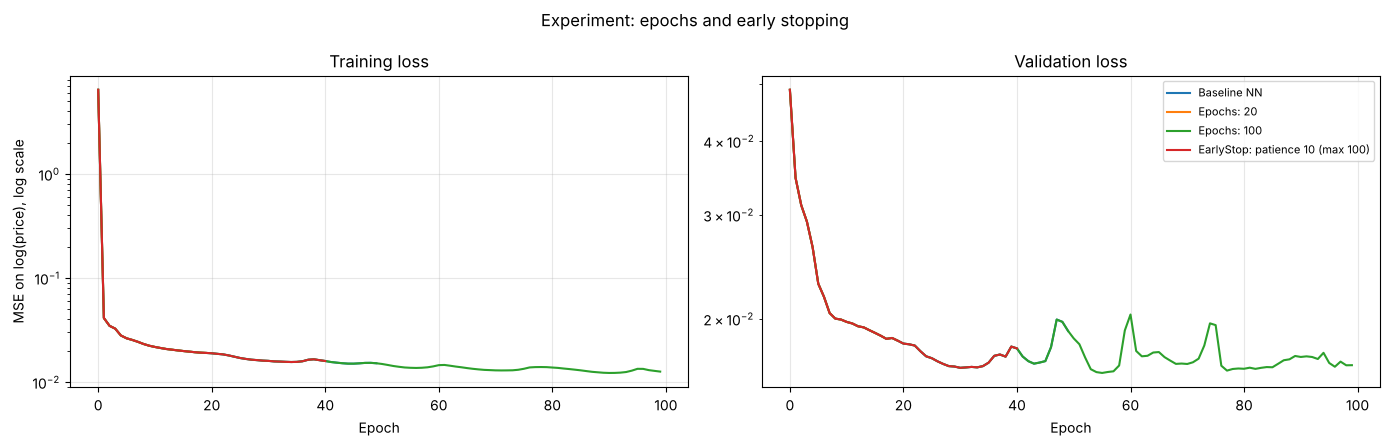

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Epochs: 20,"$106,216","$213,240",0.972,10.9,20,20,0.1094,0.1069,68
Epochs: 100,"$106,829","$224,017",0.969,10.2,100,56,0.0891,0.1019,365
EarlyStop: patience 10 (max 100),"$101,610","$203,125",0.974,10.1,41,31,0.1003,0.1059,148


In [49]:
run_experiment("Epochs: 20",  epochs=20)
run_experiment("Epochs: 100", epochs=100)
run_experiment("EarlyStop: patience 10 (max 100)", epochs=100, early_stopping=True, patience=10)

plot_curves(group(("Epochs:", "EarlyStop:")), "Experiment: epochs and early stopping")
show(("Epochs:", "EarlyStop:"))

**Results**

Compared with the baseline (50 epochs, MAPE 11.6%, R² 0.967, 194 s), all three variants scored better. Training for 20 epochs gave MAPE 10.9% (68 s) and training for 100 epochs gave 10.2% (365 s). Early stopping was best on every metric: MAPE 10.1%, MAE \$101,610, RMSE \$203,125 and R² 0.974. It stopped at epoch 41 (best epoch 31) after 148 s, which is 59% less time than the 100-epoch run. In the curves, all four runs follow the same line until they stop. In the 100-epoch run the validation loss spiked around epochs 48, 61 and 75 and dipped only slightly below its epoch-31 level (around epochs 54–58 and 78–84; lowest 0.0162 against 0.0165).

**Interpretation**

All four runs use the same seed and settings, so they follow exactly the same learning curve until they stop. The rows differ only in where training ends. Validation loss is lowest around epoch 31, so 50 epochs was already slightly too many for the baseline (it ended on a late bump), and 100 epochs was more than needed: training continued for 50 more epochs, with repeated validation spikes, for almost no gain. Twenty epochs was too short, because the training error (0.1094) was still above the validation error (0.1069), so the network had not finished learning. Early stopping gave the best result in less time than 50 or 100 epochs (148 s vs 194 s and 365 s) by returning the weights from epoch 31. The MAPE values (10.1% to 11.6%) are close to the seed range from 4.2 (11.0% to 14.8%), so the accuracy differences are small. The clear benefits are time saved and avoiding the unstable late epochs that made one seed in 4.2 end badly. The early stopping score is slightly optimistic, because the validation set chose the stopping epoch, and the test set in Section 5 gives the fair check. Each setting was trained once.

> **4.9 Experiment: L2 regularization**

**Motivation:** L2 regularization adds a penalty for large weights to the loss, which pushes the network towards simpler solutions and can reduce overfitting.

**Description:** an L2 penalty is added to the weights of the hidden layers, with strengths 0.0001, 0.001 and 0.01 (the baseline has none). Because the penalty is added to the training and validation loss, the loss values of these runs are not comparable with the other experiments, so the learning curves below use the mean absolute error (MAE) of log(price) instead.

L2: 0.0001
  MAE:  $97,470
  RMSE: $190,321
  R²:   0.978
  MAPE: 9.8%
  trained 50 epochs in 163 s



L2: 0.001
  MAE:  $99,244
  RMSE: $199,153
  R²:   0.975
  MAPE: 10.1%
  trained 50 epochs in 171 s



L2: 0.01
  MAE:  $112,871
  RMSE: $230,821
  R²:   0.967
  MAPE: 11.7%
  trained 50 epochs in 172 s



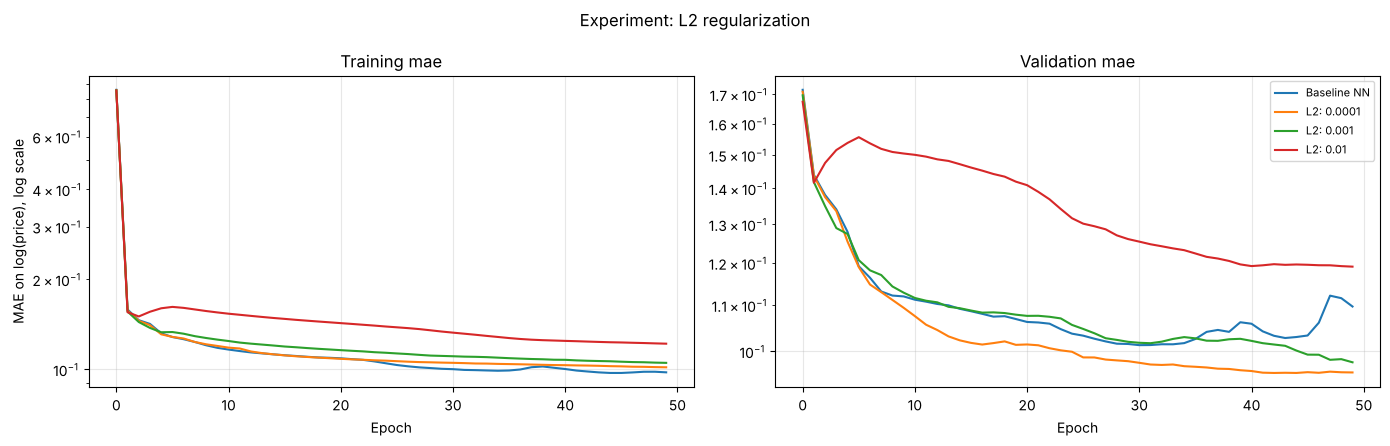

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
L2: 0.0001,"$97,470","$190,321",0.978,9.8,50,50,0.1017,0.0957,163
L2: 0.001,"$99,244","$199,153",0.975,10.1,50,50,0.1052,0.0978,171
L2: 0.01,"$112,871","$230,821",0.967,11.7,50,50,0.1220,0.1191,172


In [50]:
run_experiment("L2: 0.0001", l2=0.0001)
run_experiment("L2: 0.001",  l2=0.001)
run_experiment("L2: 0.01",   l2=0.01)

plot_curves(group("L2:"), "Experiment: L2 regularization", metric="mae")
show("L2:")

**Results**

Compared with the baseline (no L2, MAPE 11.6%, R² 0.967), the two smaller penalties improved every metric. L2 0.0001 was best: MAPE 9.8%, MAE \$97,470, RMSE \$190,321 and R² 0.978. L2 0.001 gave MAPE 10.1% and R² 0.975. The strongest penalty, 0.01, was no better than the baseline (MAPE 11.7%, R² 0.967) and had the highest training error (0.1220 against 0.0978). Training times were similar (163 to 194 s). In the curves, the baseline’s validation error rose again between about epochs 37 and 48, while the curves of L2 0.0001 and 0.001 kept decreasing. L2 0.01 rose in the first 5 epochs and stayed clearly above the others.

**Interpretation**

A small L2 penalty helped. L2 0.0001 has a MAPE of 9.8%, below all four baseline seed runs in 4.2 (11.0% to 14.8%), so the improvement is probably real, although modest (1.2 points below the best baseline seed). L2 0.001 (10.1%) is 0.9 points below that value, so it is slightly better but not clearly different. L2 0.01 (11.7%) lies inside the seed range, so it did not help. Its high training error shows underfitting: the penalty is so strong that the weights are held too small, and the network cannot fit the data well even on the training set. The curves support the overfitting explanation for the baseline, whose validation error rose late in training while the validation error of the weakly regularised networks kept falling. With L2 the validation error also ends below the training error, so the gap seen in the baseline disappears. Each strength was trained once, so these conclusions are tentative.

> **4.10 Experiment: Dropout**

**Motivation:** Dropout randomly switches off a fraction of the neurons in every training step, so the network cannot rely on a few neurons. It is another way to reduce overfitting.

**Description:** a Dropout layer is added after each hidden layer with rates 0.1, 0.2 and 0.3 (the baseline has none). Dropout is only active during training, not when predicting. This means the training curve is measured with neurons switched off, so it can sit above the validation curve.

Dropout: 0.1
  MAE:  $110,969
  RMSE: $239,362
  R²:   0.965
  MAPE: 14.2%
  trained 50 epochs in 182 s



Dropout: 0.2
  MAE:  $173,201
  RMSE: $365,524
  R²:   0.917
  MAPE: 21.8%
  trained 50 epochs in 187 s



Dropout: 0.3
  MAE:  $182,598
  RMSE: $376,091
  R²:   0.913
  MAPE: 25.6%
  trained 50 epochs in 183 s



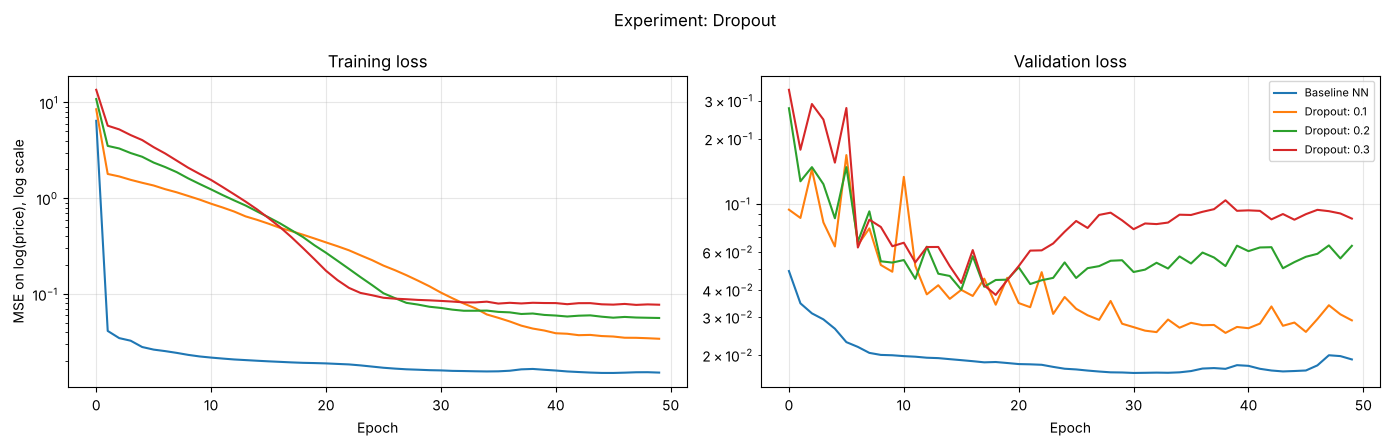

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Dropout: 0.1,"$110,969","$239,362",0.965,14.2,50,39,0.1410,0.1319,182
Dropout: 0.2,"$173,201","$365,524",0.917,21.8,50,16,0.1793,0.1981,187
Dropout: 0.3,"$182,598","$376,091",0.913,25.6,50,19,0.2092,0.2230,183


In [51]:
run_experiment("Dropout: 0.1", dropout=0.1)
run_experiment("Dropout: 0.2", dropout=0.2)
run_experiment("Dropout: 0.3", dropout=0.3)

plot_curves(group("Dropout:"), "Experiment: Dropout")
show("Dropout:")

**Results**

Dropout made the network worse in MAPE at every rate. Compared with the baseline (no Dropout, MAPE 11.6%, R² 0.967), Dropout 0.1 gave MAPE 14.2%, R² 0.965 and MAE \$110,969. Dropout 0.2 gave MAPE 21.8% and R² 0.917, and Dropout 0.3 gave MAPE 25.6% and R² 0.913. The higher the rate, the worse every metric. Training error was much higher with Dropout (0.141, 0.179 and 0.209, against 0.098 for the baseline). In the curves, the training loss of the Dropout runs fell slowly, while the baseline reached a low value within a few epochs. The validation loss of the Dropout runs was noisy and stayed above the baseline. Runs 0.2 and 0.3 reached their lowest validation loss early (epochs 16 and 19) and then rose. Training times were similar (182 to 194 s).

**Interpretation**

Dropout did not help here. Dropout 0.1’s MAPE (14.2%) is 2.6 points worse than the baseline run and near the top of the seed range from 4.2 (11.0% to 14.8%); its slightly lower MAE (\$110,969 vs \$115,781) comes with a higher RMSE and lower R², so it is no improvement. Dropout 0.2 and 0.3 are clearly worse. The cause looks like underfitting, not overfitting: the training error is high and grows with the dropout rate, so the network cannot even fit the training data well. The baseline is small (64 + 32 = 96 hidden neurons) and overfitted only mildly, since its validation loss rose only late in training. Switching off 10% to 30% of the neurons therefore removes capacity the network needs, with little overfitting left to fix. This differs from L2 in 4.9, which only shrinks the weights gently and helped slightly. The training error of the Dropout runs is measured with neurons switched off, so it overstates the error of the final network and should not be compared directly with the validation error. Each rate was trained once, and the training loss of Dropout 0.1 was still falling at epoch 50, so more epochs might narrow the gap.

# **5. Final Model**

> **5.1 Compare all experiments**

All runs from Section 4, ranked by validation MAPE (lowest = best).

In [52]:
show(sort=True)

,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Act: sigmoid,"$91,443","$185,947",0.979,9.2,50,30,0.0820,0.0901,162
Opt: SGD+momentum,"$95,912","$214,089",0.972,9.2,50,48,0.0980,0.0931,163
L2: 0.0001,"$97,470","$190,321",0.978,9.8,50,50,0.1017,0.0957,163
Opt: SGD,"$96,898","$198,733",0.976,10.0,50,48,0.1082,0.1002,156
Act: tanh,"$103,666","$231,474",0.967,10.0,50,12,0.0787,0.1008,173
Seeds-32: 2,"$98,119","$200,094",0.975,10.0,50,50,0.0947,0.0999,142
L2: 0.001,"$99,244","$199,153",0.975,10.1,50,50,0.1052,0.0978,171
LR: 0.0001,"$97,882","$196,245",0.976,10.1,50,50,0.0923,0.1002,177
EarlyStop: patience 10 (max 100),"$101,610","$203,125",0.974,10.1,41,31,0.1003,0.1059,148


> **5.2 Combine the best settings**

The best single settings do not always work well together (for example, a bigger network may need Dropout or L2 to avoid overfitting). So we train three **candidate** models that combine the best settings, compare them on the **validation** set, and keep the one with the lowest validation MAPE.

All three candidates use early stopping. **A** uses sigmoid, **B** adds L2 0.0001 to A, and **C** uses SGD with momentum and L2 0.0001. Dropout, larger networks and unstable learning rates are excluded because they did not help in Section 4.

In [53]:
# Three candidates built from the best single settings in the results table.
# All use early stopping with a cap of 200 epochs, because several good settings
# (SGD with momentum, small learning rates) were still improving at epoch 50.
CANDIDATES = {
    # A: the best single setting (sigmoid) + early stopping. This is the control.
    "Final A": dict(hidden=(64, 32), activation="sigmoid", optimizer="adam", lr=0.001,
                    batch_size=32, epochs=200, early_stopping=True),

    # B: A + the best regularizer (L2 0.0001). Does L2 add anything on top of A?
    "Final B": dict(hidden=(64, 32), activation="sigmoid", optimizer="adam", lr=0.001,
                    batch_size=32, epochs=200, early_stopping=True, l2=0.0001),

    # C: the other strong family: SGD with momentum + L2 0.0001 + early stopping.
    "Final C": dict(hidden=(64, 32), activation="relu", optimizer="sgd_momentum", lr=0.01,
                    batch_size=32, epochs=200, early_stopping=True, l2=0.0001),
}

# Train every candidate on the training set (validation set is used for early stopping)
candidate_models = {name: run_experiment(name, **cfg) for name, cfg in CANDIDATES.items()}
show("Final")

Final A
  MAE:  $89,397
  RMSE: $179,721
  R²:   0.980
  MAPE: 8.9%
  trained 40 epochs in 130 s



Final B
  MAE:  $93,879
  RMSE: $204,445
  R²:   0.974
  MAPE: 9.0%
  trained 200 epochs in 681 s



Final C
  MAE:  $97,389
  RMSE: $211,377
  R²:   0.972
  MAPE: 9.7%
  trained 134 epochs in 421 s



,MAE,RMSE,R2,MAPE (%),epochs_run,best_epoch,train_mae,val_mae,seconds
Model,,,,,,,,,
Baseline NN,"$115,781","$231,542",0.967,11.6,50,31,0.0978,0.1097,194
Final A,"$89,397","$179,721",0.980,8.9,40,30,0.0836,0.0890,130
Final B,"$93,879","$204,445",0.974,9.0,200,200,0.0914,0.0910,681
Final C,"$97,389","$211,377",0.972,9.7,134,124,0.0928,0.0955,421


Best candidate on validation: Final A | MAPE: 8.89


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        15,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,653 (201.77 KB)

 Trainable params: 17,217 (67.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 34,436 (134.52 KB)

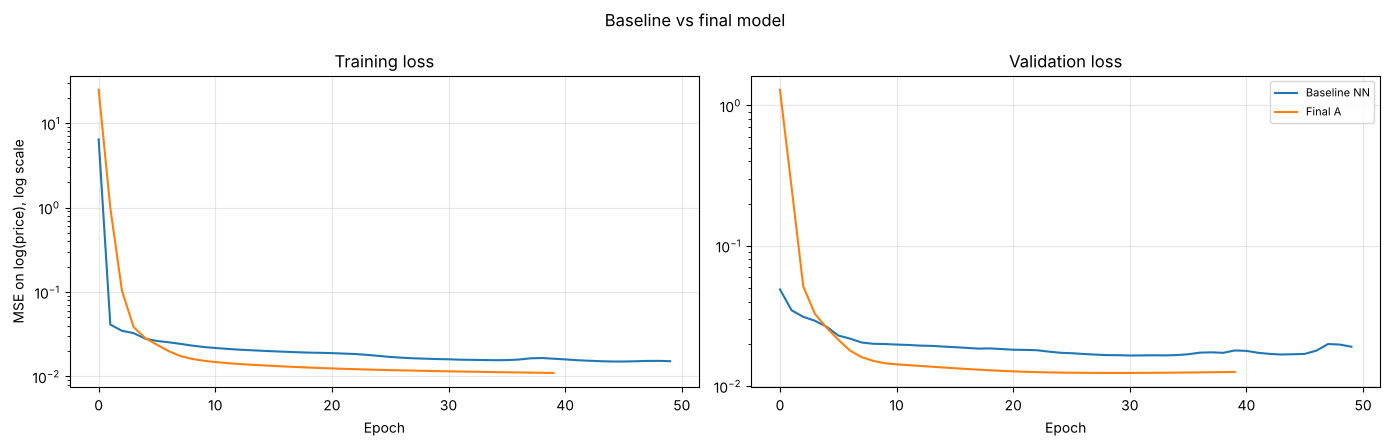

In [54]:
# Pick the candidate with the lowest validation MAPE (our rule from the start)
val_mape = pd.DataFrame(results).set_index("Model")["MAPE (%)"]
BEST_NAME = val_mape[list(CANDIDATES)].idxmin()
print("Best candidate on validation:", BEST_NAME, "| MAPE:", round(val_mape[BEST_NAME], 2))

# BEST_NAME = "Final A"     # <- remove the # and edit this line only to override the automatic choice

final_model = candidate_models[BEST_NAME]
final_model.summary()
plot_curves(["Baseline NN", BEST_NAME], "Baseline vs final model")

**Results**: Candidate A (sigmoid activation with early stopping) had the lowest validation MAPE (8.9%) and the best MAE (\$89,397), RMSE (\$179,721) and R² (0.980). Candidate B (9.0%) was within 0.1 points; candidate C (9.7%) was 0.8 points behind. A also trained fastest: it stopped at epoch 40 after 130 s. B ran all 200 epochs (681 s) without early stopping triggering, and C stopped at epoch 134 (best epoch 124) after 421 s.

**Interpretation**: adding L2 regularisation (B) or switching to SGD with momentum and L2 (C) did not improve on sigmoid alone, so the best single settings did not combine into a better model. A and B differ by less than the run-to-run variation from 4.2, so we choose A because it is the simplest and cheapest. B reached the 200-epoch limit while still improving, so it might gain from more epochs, which we did not test. The validation score of A is slightly optimistic, because it was chosen from many runs using the same validation set, so the test set in 5.3 gives the fair estimate.

> **5.3 Final evaluation on the test set**

The test set (7,500 properties) has not been used for training, for choosing hyperparameters, or for early stopping. It is used **once**, here, to measure how well the final model works on completely new properties. This is the official result of the project.

In [55]:
# Predict the test set with the final model (log scale)
final_pred_log = final_model.predict(X_test_p, verbose=0).ravel()

# Official test score with the same evaluate() function used for every model
TEST_NAME = "TEST: " + BEST_NAME
results[:] = [r for r in results if r["Model"] != TEST_NAME]   # re-running replaces the row
evaluate(TEST_NAME, y_test, final_pred_log)

# Test result next to the validation results of the reference models
summary = pd.DataFrame(results).set_index("Model").loc[
    ["Median predictor", "Baseline NN", BEST_NAME, TEST_NAME]]
summary.index = ["Median predictor (validation)", "Baseline NN (validation)",
                 BEST_NAME + " (validation)", BEST_NAME + " (TEST)"]
summary.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.3f}", "MAPE (%)": "{:.1f}"})

TEST: Final A
  MAE:  $85,054
  RMSE: $162,490
  R²:   0.980
  MAPE: 8.8%


,MAE,RMSE,R2,MAPE (%)
Median predictor (validation),"$760,202","$1,343,356",-0.116,143.4
Baseline NN (validation),"$115,781","$231,542",0.967,11.6
Final A (validation),"$89,397","$179,721",0.980,8.9
Final A (TEST),"$85,054","$162,490",0.980,8.8


> **"Accuracy" for a regression model**

Accuracy (the share of correct answers) is a classification metric: a price prediction is never exactly "correct" to the dollar. For a regression model we report MAE, RMSE, R² and MAPE above. To give an intuitive accuracy-style figure, we also measure **the share of test properties whose predicted price is within ±5%, ±10% and ±20% of the actual price**.

In [56]:
actual = np.exp(y_test.values)
predicted = np.exp(final_pred_log)
abs_pct_error = np.abs(predicted - actual) / actual * 100

within = pd.DataFrame({
    "Tolerance": ["within ±5%", "within ±10%", "within ±20%"],
    "Share of test properties": [(abs_pct_error <= t).mean() * 100 for t in (5, 10, 20)],
}).set_index("Tolerance")
print(f"Test MAPE: {abs_pct_error.mean():.1f}%  ->  average 'accuracy' about {100 - abs_pct_error.mean():.1f}%")
within.style.format("{:.1f}%")

Test MAPE: 8.8%  ->  average 'accuracy' about 91.2%


,Share of test properties
Tolerance,
within ±5%,35.1%
within ±10%,64.3%
within ±20%,93.2%


**Results**

On the test set (7,500 properties never used for training, tuning or early stopping), the final model (Final A: sigmoid activation with early stopping) achieved MAE \$85,054, RMSE \$162,490, R² 0.980 and MAPE 8.8%.

As an accuracy-style measure, 35.1% of test properties were predicted within ±5% of their actual price, 64.3% within ±10%, and 93.2% within ±20%. Put simply, the average prediction is about 91% accurate (100% − MAPE).

**Interpretation**

   The test results match the validation results closely: the same R² (0.980) and almost the same MAPE (8.8% vs 8.9%). The model therefore generalises well to new properties. The validation score was also not inflated by choosing the final model from many runs on the same validation set, which was a risk we noted in 5.2. The test MAE and RMSE are even slightly lower than on validation. This is most likely random variation in which expensive properties ended up in each set, not a real improvement, since a few luxury properties have a large effect on dollar errors.

   Nine in ten properties are priced within ±20%, so the model is useful as a first estimate of a fair price. Only about two-thirds fall within ±10%, however, so it is not precise enough to replace a professional valuation of an individual property. As Section 5.5 shows, the larger errors are concentrated in rare, high-value properties.

> **5.3b How the accuracy was improved: from 46.5% to 91.2%**


Nine in ten properties are priced within ±20%, so the model is useful as a first estimate of a fair price. Only about two-thirds fall within ±10%, however, so it is not precise enough to replace a professional valuation of an individual property. As Section 5.5 shows, the larger errors are concentrated in rare, high-value properties.

In this section, "accuracy" means **100% − MAPE**, the average closeness of the predicted price to the real price. It is an informal, easy-to-explain version of MAPE, not classification accuracy.

**1. Starting point**

- **Median predictor (no learning):** MAPE 143.4%, R² −0.116. It ignores every feature, so its "accuracy" is meaningless.
- **Simplest model:** linear regression on area and bedrooms reached only **20.6%** accuracy (MAPE 79.4%).
- **First neural network:** trained on the raw numeric features and raw prices, it reached **46.5%** accuracy (MAPE 53.5%, R² 0.624). This is the real starting point of our network.

**2. Data preparation: from 46.5% to 88.4% (Section 3.1)**

We added our preparation steps one at a time and measured each one:
- **StandardScaler:** 46.5% → 53.2%. Puts all inputs on the same scale and stabilizes training.
- **log(price) target:** 53.2% → 78.5%. Makes errors relative, so cheap and expensive properties count equally.
- **One-hot location and property features:** 78.5% → **88.4%** (R² 0.967). Location is the strongest price driver.

This gave the **Baseline NN** (MAPE 11.6%). It still had three weaknesses:
1. **Mild overfitting:** after about epoch 31 the validation loss stopped improving and became unstable.
2. **Run-to-run noise:** four seeds gave MAPE between 11.0% and 14.8%.
3. **Untested hyperparameters:** all settings were defaults.

Other preparation decisions were not measured separately, but they protect the result:
- removing the leakage columns (`price_per_sqft_usd`, `price_per_m2_usd`)
- setting `floor` and `total_floors` to 0 for villas
- validating the raw data at load time, after a corrupted CSV row turned the training loss into NaN

**3. Method: change one thing at a time**

We built a reusable `run_experiment()` function in Keras that resets the random seed, trains a model, evaluates it on the validation set and saves the result. Each experiment changed **only one setting** compared with the baseline. A change only counted as a real improvement if it beat the baseline by more than the seed noise (about 1–2 points of MAPE).

**4. What increased the accuracy**

| Change (one at a time) | Validation MAPE | ≈ Accuracy | Why it helped |
|---|---|---|---|
| Baseline (ReLU) | 11.6% | 88.4% | reference |
| Early stopping (patience 10) | 10.1% | 89.9% | stops at the best epoch (31) and restores those weights, avoiding the unstable late epochs |
| L2 regularization 0.0001 | 9.8% | 90.2% | a small penalty on large weights reduced overfitting |
| SGD with momentum | 9.2% | 90.8% | smoother, slower learning with a smaller train/validation gap |
| **Sigmoid activation** | **9.2%** | **90.8%** | lowest and most stable validation loss; the network is shallow, so vanishing gradients were not a problem |

**5. Examples where accuracy was low, and what we did about it**

- **Learning rate too high:** with a learning rate of **0.1**, the MAPE was **14.2%** (about **85.8% accuracy**) and R² was 0.935, below every baseline seed. The first weight updates overshot, and the network then got stuck on a plateau, with the highest training error of all runs without Dropout. In an earlier run of this notebook the same setting collapsed completely (MAPE about 147%), which shows how unstable a too-large learning rate is. **Fix:** we used a smaller learning rate. The default 0.001 gave 11.6%, and 0.0001 gave 10.1% (about 89.9% accuracy).
- **Too much Dropout:** Dropout 0.3 gave a MAPE of **25.6%** (about **74.4% accuracy**). The training error was more than twice the baseline's (0.209 vs 0.098), which showed **underfitting**: switching off 30% of the neurons removed capacity that this small network needed. **Fix:** we removed Dropout and used a gentle L2 penalty instead, which gave 9.8% (about **90.2% accuracy**).
- **Network too large:** the 256 → 128 → 64 network gave a MAPE of **15.1%** (about **84.9% accuracy**). Its training error was lower than the baseline's, but its validation error was much higher, and its validation curve spiked repeatedly, which is **overfitting**. **Fix:** we kept the small network. A single 32-neuron layer gave 10.5%, and repeating it with four seeds confirmed it was consistently better than the baseline (mean 10.3%).

**6. Combining the best settings**

We trained three candidates, all with early stopping (maximum 200 epochs):
- **A:** sigmoid
- **B:** sigmoid + L2 0.0001
- **C:** SGD with momentum + L2 0.0001

They scored 8.9%, 9.0% and 9.7% on validation. Combining settings did not stack: B and C were no better than A. We chose **A** because it was the simplest and fastest (it stopped at epoch 40, after 130 s).

**7. Final result on the test set**

On 7,500 properties never used for training or tuning, Final A achieved **MAPE 8.8%, about 91.2% accuracy**, with R² 0.980, MAE \$85,054 and RMSE \$162,490. In addition, 64.3% of properties were predicted within ±10%, and 93.2% within ±20%.

Compared with the first neural network (46.5%) and the baseline (88.4%), the final model reached 91.2%. Against the baseline, it:
- cut the MAPE from **11.6% to 8.8%** (about a quarter less error)
- cut the MAE by **27%** and the RMSE by **30%**

The larger fall in RMSE shows that the improvements mainly reduced the biggest errors.

**8. What could increase it further**

- Average several models trained with different seeds (an ensemble).
- Add engineered features, such as property age and area per bedroom.
- Use embedding layers for `community` instead of one-hot encoding.
- Use a learning-rate schedule such as `ReduceLROnPlateau`.
- Use a time-based split to test how well the model predicts future listings.


> **5.4 Actual vs predicted prices**

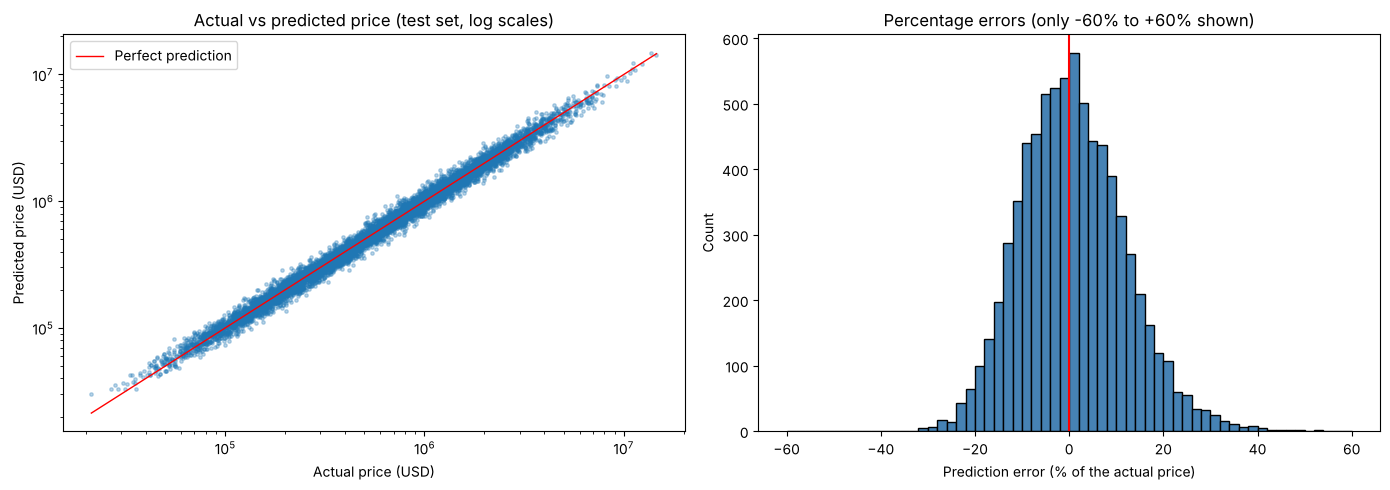

Predictions with an error beyond +/-60%: 0 of 7500


In [57]:
pct_error = (predicted - actual) / actual * 100   # signed: + = over-prediction, - = under-prediction

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(actual, predicted, s=6, alpha=0.3)
limits = [actual.min(), actual.max()]
axes[0].plot(limits, limits, color="red", linewidth=1, label="Perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Actual price (USD)")
axes[0].set_ylabel("Predicted price (USD)")
axes[0].set_title("Actual vs predicted price (test set, log scales)")
axes[0].legend()

axes[1].hist(pct_error, bins=60, range=(-60, 60), color="steelblue", edgecolor="black")
axes[1].axvline(0, color="red")
axes[1].set_xlabel("Prediction error (% of the actual price)")
axes[1].set_ylabel("Count")
axes[1].set_title("Percentage errors (only -60% to +60% shown)")

plt.tight_layout()
plt.show()
print("Predictions with an error beyond +/-60%:", int((np.abs(pct_error) > 60).sum()), "of", len(pct_error))

In [58]:
# Bias check: is the model systematically too high or too low, overall and by price level?
print(f"Median signed error: {np.median(pct_error):.2f}%   |   Mean signed error: {pct_error.mean():.2f}%")

quintile = pd.qcut(actual, 5, labels=["Cheapest 20%", "2nd 20%", "Middle 20%", "4th 20%", "Most expensive 20%"])
bias = pd.DataFrame({"pct_error": pct_error, "quintile": quintile}).groupby("quintile", observed=True)["pct_error"]
bias_table = pd.DataFrame({"listings": bias.size(), "median signed error (%)": bias.median()})
bias_table.style.format({"median signed error (%)": "{:+.2f}"})

Median signed error: 0.15%   |   Mean signed error: 0.73%


,listings,median signed error (%)
quintile,,
Cheapest 20%,1500,+2.32
2nd 20%,1500,-0.83
Middle 20%,1500,+0.40
4th 20%,1501,-0.07
Most expensive 20%,1499,-0.46


**Interpretation**:

The points follow the red line very closely across the whole price range, from about \$20,000 to over \$10 million. The predictions form a narrow band around the perfect-prediction line, so the model has learned the price level well. The spread is widest for the cheapest properties, where the cloud is loosest and there are few points. It is tightest for middle-priced properties, where most of the data lies. The expensive end is also fairly tight, though the few very expensive properties sit a little below the line. Median errors by price quintile (table above) confirm this: the cheapest fifth of properties is over-predicted by about 2.3%, while the other four groups stay within about ±1%. The most expensive properties are under-predicted by only about 0.5%, so any bias at the top is negligible.

The histogram supports this. The errors are centred close to 0%, so there is no strong overall bias towards over- or under-prediction. Most errors fall within about ±20%. The right tail is longer than the left, reaching about +50% against about -35%, because the model predicts in log prices. The same error in log terms is a larger percentage when the model over-predicts than when it under-predicts. No prediction is off by more than 60% (0 of 7,500). The median error is 0.15% and the mean error is 0.73%, so the model neither over- nor under-predicts in a meaningful way overall. The mean sits slightly above the median because a few large over-predictions stretch the right tail.

> **5.5 Where does the model make its biggest errors?**

In [59]:
from IPython.display import display

errors = X_test[["community", "property_category", "property_type", "bedrooms", "area_sqft"]].copy()
errors["actual"] = actual
errors["predicted"] = predicted
errors["abs_error"] = (errors["predicted"] - errors["actual"]).abs()
errors["pct_error"] = errors["abs_error"] / errors["actual"] * 100

money = "${:,.0f}"

print("By property category (villa vs apartment):")
display(errors.groupby("property_category").agg(
    listings=("actual", "size"), avg_price=("actual", "mean"),
    MAE=("abs_error", "mean"), MAPE=("pct_error", "mean")
).style.format({"avg_price": money, "MAE": money, "MAPE": "{:.1f}%"}))

errors["price_band"] = pd.qcut(errors["actual"], 4,
    labels=["Cheapest 25%", "Lower-middle 25%", "Upper-middle 25%", "Most expensive 25%"])
print("\nBy price band (cheap vs expensive):")
display(errors.groupby("price_band", observed=True).agg(
    listings=("actual", "size"), avg_price=("actual", "mean"),
    MAE=("abs_error", "mean"), MAPE=("pct_error", "mean")
).style.format({"avg_price": money, "MAE": money, "MAPE": "{:.1f}%"}))

print("\nCommunities with the highest average percentage error (at least 30 test listings):")
display(errors.groupby("community").agg(listings=("actual", "size"), MAPE=("pct_error", "mean"))
        .query("listings >= 30").sort_values("MAPE", ascending=False).head(5)
        .style.format({"MAPE": "{:.1f}%"}))

print("\nThe 10 largest errors in USD:")
display(errors.sort_values("abs_error", ascending=False).head(10)
        .drop(columns="price_band")
        .style.format({"actual": money, "predicted": money, "abs_error": money, "pct_error": "{:.1f}%"}))

By property category (villa vs apartment):


,listings,avg_price,MAE,MAPE
property_category,,,,
apartment,4841,"$564,369","$50,339",8.9%
villa,2659,"$1,751,916","$148,256",8.5%



By price band (cheap vs expensive):


,listings,avg_price,MAE,MAPE
price_band,,,,
Cheapest 25%,1875,"$143,146","$12,960",9.2%
Lower-middle 25%,1876,"$391,750","$33,772",8.6%
Upper-middle 25%,1874,"$914,433","$79,653",8.7%
Most expensive 25%,1875,"$2,492,527","$213,855",8.5%



Communities with the highest average percentage error (at least 30 test listings):


,listings,MAPE
community,,
Jumeirah Park,76,10.9%
Remraam,84,10.7%
Dubai Production City,87,10.4%
Dubai Harbour,81,10.1%
Dubai Islands,87,10.0%



The 10 largest errors in USD:


,community,property_category,property_type,bedrooms,area_sqft,actual,predicted,abs_error,pct_error
2029,Emirates Hills,villa,6BR_villa,6,7226,"$7,768,000","$6,119,816","$1,648,184",21.2%
48298,La Mer,villa,5BR_villa,5,5167,"$7,051,200","$5,449,706","$1,601,494",22.7%
5145,Bulgari Resort,villa,5BR_villa,5,4089,"$8,202,100","$9,757,362","$1,555,262",19.0%
38465,Jumeirah Bay Island,villa,5BR_villa,5,4691,"$10,354,800","$8,838,739","$1,516,061",14.6%
18612,Bulgari Resort,apartment,4BR_penthouse,4,1753,"$3,632,200","$5,086,490","$1,454,290",40.0%
36067,Sobha Hartland,villa,6BR_villa,6,7121,"$6,070,100","$4,767,955","$1,302,145",21.5%
9959,Bulgari Resort,apartment,4BR_penthouse,4,1519,"$4,453,500","$5,752,338","$1,298,838",29.2%
23261,Mohammed Bin Rashid City,villa,6BR_villa,6,6591,"$5,464,200","$4,192,840","$1,271,360",23.3%
10085,World Islands,villa,6BR_villa,6,6635,"$5,220,300","$6,487,728","$1,267,427",24.3%
43473,Jumeirah 1,villa,6BR_villa,6,8393,"$3,301,000","$4,537,646","$1,236,647",37.5%


**Interpretation**:

Villas and apartments are predicted about equally well in percentage terms (MAPE 8.5% vs 8.9%), so neither is clearly harder. In dollars the gap is large (\$148,256 vs \$50,339) because villas cost far more on average (about \$1.75M vs \$564K).

The price bands show the same pattern. The dollar error grows with price, from about \$13,000 in the cheapest quarter to about \$214,000 in the most expensive. The percentage error is slightly higher for cheap properties (9.2% vs 8.5%), since a small dollar difference is a bigger share of a low price, and cheap properties may differ in ways the features miss, such as condition or view. The communities with the highest MAPE (Jumeirah Park, Remraam, Dubai Production City, Dubai Harbour and Dubai Islands) are only 10 to 11%, so no community is predicted badly.

The 10 largest errors in dollars are mostly 5 to 6 bedroom villas of 4,000 to 8,400 sq ft in prestige communities such as Emirates Hills, Bulgari Resort, Jumeirah Bay Island and La Mer. Most are off by only 15 to 25%, which is the normal percentage error applied to a very high price. Likely explanations:

- Top-end prices depend on things the data lacks, such as plot size, sea view and finish.
- There are few comparable sales in these exclusive communities.
- The two 4-bedroom Bulgari Resort penthouses have the largest percentage errors (40.0% and 29.2%) because penthouses are rare and individually priced.

Overall, the model is reliable for typical properties, and the biggest errors come from rare, high-value ones.

> **5.6 Save the final model**

We save the trained network **and** the preprocessor (one-hot encoder + scaler fitted on the training data). The demo needs both: a new property must go through the same preprocessing before the network can predict its price.

In [60]:
import joblib

final_model.save("dubai_price_model.keras")
joblib.dump(preprocessor, "preprocessor.joblib")

# Check 1: the reloaded model gives the same predictions as the model in memory
reloaded_model = keras.models.load_model("dubai_price_model.keras")
same = np.allclose(reloaded_model.predict(X_test_p, verbose=0).ravel(), final_pred_log, atol=1e-4)
print("Reloaded model gives the same predictions:", same)

# Check 2: raw property row -> preprocessing -> predicted price (this is how the demo will work)
reloaded_preprocessor = joblib.load("preprocessor.joblib")
one_property = X_test.iloc[[0]]
price = np.exp(reloaded_model.predict(reloaded_preprocessor.transform(one_property).astype("float32"), verbose=0))[0, 0]
print(f"Predicted price: ${price:,.0f}   |   actual price: ${np.exp(y_test.iloc[0]):,.0f}")

try:
    from google.colab import files
    files.download("dubai_price_model.keras")
    files.download("preprocessor.joblib")
    files.download("experiment_log.json")
except ImportError:
    print("Not running in Colab - the files are in the current folder.")

Reloaded model gives the same predictions: True
Predicted price: $2,047,383   |   actual price: $1,976,600
Not running in Colab - the files are in the current folder.
